#RealNetwork

##Pre

In [ ]:
#Preperation

!pip install gdown -q
import gdown
import os
import shutil

folder_url = 'https://drive.google.com/drive/folders/1QkKjqtou8BakduPGnay39LB2OuZk0m3I'

# Benthimer 'https://drive.google.com/drive/folders/1QkKjqtou8BakduPGnay39LB2OuZk0m3I'
# Heletz 'https://drive.google.com/drive/folders/1J2OYy2nWMkZGml9wuFhTDUPvSLWCp2gK'
# Berea   'https://drive.google.com/drive/folders/1ALBrn2OHyAnjEmK-1c6zhfTUOoVknQXT'
# Lv60B 'https://drive.google.com/drive/folders/1HVlIkTin2to01NLhDeF8b3jnDfpqyrrD'
# F42B   'https://drive.google.com/drive/folders/19BxsSsal0Iqg79VfL6ubqSER1VfyzfvV'
# A1    'https://drive.google.com/drive/folders/1Pmv3XDdyXkTxdSgwyB5x0reuu1pZYsWJ'


# دانلود پوشه
gdown.download_folder(folder_url, quiet=False, remaining_ok=True)

folder_name = 'Bentheimer'

#'Bentheimer'  # یا می‌تونید از URL استخراج کنید
# 'Heletz'
# 'Berea'   Lv60B   F42B   A1


if os.path.exists(folder_name):
    # انتقال همه فایل‌ها به پوشه فعلی
    for file_name in os.listdir(folder_name):
        src = os.path.join(folder_name, file_name)
        dst = os.path.join('.', file_name)
        shutil.move(src, dst)
    # پاک کردن پوشه خالی
    os.rmdir(folder_name)

import numpy as np
from collections import deque, defaultdict
import os

def read_node_files(node1_path, node2_path):
    """
    خواندن فایل‌های node1.dat و node2.dat
    """
    # خواندن node1.dat
    with open(node1_path, 'r') as f:
        lines = f.readlines()

    # خط اول: تعداد حفره‌ها و ابعاد شبکه
    first_line = lines[0].strip().split()
    num_pores = int(first_line[0])
    network_dims = [float(first_line[1]), float(first_line[2]), float(first_line[3])]

    # دیکشنری‌ها برای ذخیره اطلاعات
    pore_connections = {}  # اتصالات هر حفره
    pore_inlet_outlet = {}  # وضعیت ورودی/خروجی
    pore_neighbors = {}    # همسایه‌ها
    pore_throats = {}      # گلوگاه‌های متصل
    pore_coords = {}       # مختصات حفره‌ها

    # خواندن اطلاعات هر حفره
    for line in lines[1:1+num_pores]:
        parts = list(map(float, line.strip().split()))
        pore_id = int(parts[0])

        # مختصات
        x, y, z = parts[1], parts[2], parts[3]
        pore_coords[pore_id] = [x, y, z]

        num_conn = int(parts[4])

        # استخراج اطلاعات
        start_idx = 5
        neighbors = []
        if num_conn > 0:
            neighbors = list(map(int, parts[start_idx:start_idx + num_conn]))
            start_idx += num_conn

        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx + 1]) if len(parts) > start_idx + 1 else 0
        start_idx += 2

        throat_connections = []
        if num_conn > 0 and len(parts) > start_idx:
            throat_connections = list(map(int, parts[start_idx:start_idx + num_conn]))

        # ذخیره اطلاعات
        pore_connections[pore_id] = num_conn
        pore_inlet_outlet[pore_id] = (inlet_status, outlet_status)
        pore_neighbors[pore_id] = neighbors
        pore_throats[pore_id] = throat_connections

    # خواندن node2.dat برای حجم حفره‌ها
    pore_volumes = {}
    pore_radii = {}

    with open(node2_path, 'r') as f:
        lines = f.readlines()

    for line in lines:
        parts = list(map(float, line.strip().split()))
        pore_id = int(parts[0])
        pore_volumes[pore_id] = float(parts[1])  # حجم حفره
        pore_radii[pore_id] = float(parts[2])    # شعاع حفره

    # تبدیل دیکشنری‌ها به آرایه‌های numpy با ترتیب صحیح
    sorted_ids = sorted(pore_coords.keys())

    pore_coords_array = np.array([pore_coords[i] for i in sorted_ids])
    pore_radii_array = np.array([pore_radii[i] for i in sorted_ids])
    pore_volumes_array = np.array([pore_volumes[i] for i in sorted_ids])

    # ساخت neighbor_list به صورت لیست لیست
    neighbor_list = [pore_neighbors[i] for i in sorted_ids]

    return {
        'num_pores': num_pores,
        'network_dims': network_dims,
        'pore_connections': pore_connections,
        'pore_inlet_outlet': pore_inlet_outlet,
        'pore_neighbors': pore_neighbors,
        'pore_throats': pore_throats,
        'pore_volumes': pore_volumes,
        'pore_radii': pore_radii,
        'pore_coords': pore_coords_array,
        'pore_radii_array': pore_radii_array,
        'pore_volumes_array': pore_volumes_array,
        'neighbor_list': neighbor_list
    }

def read_link_files(link1_path, link2_path):
    """
    خواندن فایل‌های link1.dat و link2.dat
    """
    # خواندن link1.dat
    with open(link1_path, 'r') as f:
        lines = f.readlines()

    num_throats = int(lines[0].strip())
    throat_info = {}

    for line in lines[1:1+num_throats]:
        parts = list(map(float, line.strip().split()))
        throat_id = int(parts[0])
        pore1 = int(parts[1])
        pore2 = int(parts[2])
        radius = float(parts[3])
        shape_factor = float(parts[4])
        length = float(parts[5])

        throat_info[throat_id] = {
            'pore1': pore1,
            'pore2': pore2,
            'radius': radius,
            'shape_factor': shape_factor,
            'length': length
        }

    # خواندن link2.dat برای اطلاعات تکمیلی
    throat_volumes = {}

    with open(link2_path, 'r') as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        if i >= num_throats:
            break
        parts = list(map(float, line.strip().split()))
        throat_id = int(parts[0])
        throat_volume = float(parts[6])  # حجم گلوگاه
        throat_volumes[throat_id] = throat_volume

    # اضافه کردن حجم به اطلاعات گلوگاه‌ها
    for throat_id, volume in throat_volumes.items():
        if throat_id in throat_info:
            throat_info[throat_id]['volume'] = volume

    # ایجاد آرایه‌ای از داده‌های گلوگاه‌ها
    throat_data = []
    for throat_id in sorted(throat_info.keys()):
        t = throat_info[throat_id]
        throat_data.append([
            t['pore1'], t['pore2'], t['radius'],
            t['length'], t.get('volume', 0.0), t['shape_factor']
        ])

    return {
        'num_throats': num_throats,
        'throat_info': throat_info,
        'throat_data': np.array(throat_data)
    }

def find_connected_components(pore_neighbors):
    """
    پیدا کردن اجزای متصل شبکه
    """
    # ساخت گراف کامل از اتصالات
    graph = defaultdict(list)
    all_pores = set()

    # اضافه کردن اتصالات بین حفره‌ها
    for pore_id, neighbors in pore_neighbors.items():
        all_pores.add(pore_id)
        for neighbor in neighbors:
            if neighbor > 0:  # فقط حفره‌های واقعی (نه مخازن)
                graph[pore_id].append(neighbor)
                graph[neighbor].append(pore_id)
                all_pores.add(neighbor)

    # الگوریتم DFS برای پیدا کردن اجزای متصل
    visited = set()
    components = []

    def dfs(pore, component):
        stack = [pore]
        while stack:
            current = stack.pop()
            if current not in visited:
                visited.add(current)
                component.append(current)
                for neighbor in graph[current]:
                    if neighbor not in visited:
                        stack.append(neighbor)

    for pore in all_pores:
        if pore not in visited and pore in graph:
            component = []
            dfs(pore, component)
            components.append(component)

    # مرتب کردن بر اساس تعداد حفره‌ها
    components.sort(key=len, reverse=True)

    return components

def find_pores_connected_to_inlet_outlet(pore_neighbors, pore_inlet_outlet):
    """
    پیدا کردن حفره‌های متصل به ورودی/خروجی
    """
    # ساخت گراف
    graph = defaultdict(list)
    all_pores = set()

    for pore_id, neighbors in pore_neighbors.items():
        all_pores.add(pore_id)
        for neighbor in neighbors:
            graph[pore_id].append(neighbor)
            if neighbor > 0:
                all_pores.add(neighbor)

    # حفره‌های متصل به ورودی (شماره -1)
    inlet_connected = set()
    # حفره‌های متصل به خروجی (شماره 0)
    outlet_connected = set()

    # BFS از حفره‌هایی که مستقیماً به ورودی/خروجی متصل هستند
    for pore_id, (inlet_status, outlet_status) in pore_inlet_outlet.items():
        if inlet_status == 1:
            # این حفره مستقیماً به ورودی متصل است
            # تمام حفره‌های متصل به آن را پیدا می‌کنیم
            queue = deque([pore_id])
            visited = set()
            while queue:
                current = queue.popleft()
                if current not in visited and current > 0:  # فقط حفره‌های واقعی
                    visited.add(current)
                    inlet_connected.add(current)
                    for neighbor in graph[current]:
                        if neighbor > 0 and neighbor not in visited:
                            queue.append(neighbor)

        if outlet_status == 1:
            # این حفره مستقیماً به خروجی متصل است
            queue = deque([pore_id])
            visited = set()
            while queue:
                current = queue.popleft()
                if current not in visited and current > 0:
                    visited.add(current)
                    outlet_connected.add(current)
                    for neighbor in graph[current]:
                        if neighbor > 0 and neighbor not in visited:
                            queue.append(neighbor)

    # حفره‌هایی که به هر دو یا یکی متصل هستند
    connected_to_reservoirs = inlet_connected.union(outlet_connected)

    return connected_to_reservoirs, inlet_connected, outlet_connected

def calculate_porosity(node_data, link_data, connected_pores=None):
    """
    محاسبه تخلخل
    """
    # حجم کل نمونه
    dims = node_data['network_dims']
    total_sample_volume = dims[0] * dims[1] * dims[2]

    # اگر مجموعه‌ای از حفره‌های متصل داده نشده، همه حفره‌ها را در نظر بگیر
    if connected_pores is None:
        connected_pores = set(node_data['pore_volumes'].keys())

    # محاسبه حجم کل حفره‌های متصل
    total_pore_volume = 0
    for pore_id in connected_pores:
        if pore_id in node_data['pore_volumes']:
            total_pore_volume += node_data['pore_volumes'][pore_id]

    # محاسبه حجم کل گلوگاه‌ها (اختیاری - برای دقت بیشتر)
    total_throat_volume = 0
    for throat_id, info in link_data['throat_info'].items():
        if 'volume' in info:
            total_throat_volume += info['volume']

    # تخلخل
    porosity = (total_pore_volume / total_sample_volume) * 100
    porosity_with_throats = ((total_pore_volume + total_throat_volume) / total_sample_volume) * 100

    return {
        'total_sample_volume': total_sample_volume,
        'total_pore_volume': total_pore_volume,
        'total_throat_volume': total_throat_volume,
        'porosity': porosity,
        'porosity_with_throats': porosity_with_throats,
        'num_connected_pores': len(connected_pores),
        'connected_pores_ratio': len(connected_pores) / node_data['num_pores'] * 100
    }

def prepare_network_for_actor_critic(node_data, link_data, connected_pores):
    """
    آماده‌سازی داده‌های شبکه برای استفاده در Actor-Critic
    """
    print("🔄 آماده‌سازی داده‌های شبکه برای Actor-Critic...")

    # حجم کل نمونه
    dims = node_data['network_dims']
    total_sample_volume = dims[0] * dims[1] * dims[2]

    # محاسبه حجم کل حفره‌ها
    total_pore_volume = np.sum(node_data['pore_volumes_array'])

    # محاسبه حجم کل گلوگاه‌ها
    total_throat_volume = np.sum([info.get('volume', 0) for info in link_data['throat_info'].values()])

    # تخلخل کل
    porosity_total = ((total_pore_volume + total_throat_volume) / total_sample_volume) * 100

    # محاسبه درجه اتصال متوسط
    neighbor_counts = [len(neighbors) for neighbors in node_data['neighbor_list']]
    avg_degree = np.mean(neighbor_counts)

    # آماده‌سازی داده‌های شبکه
    network_data = {
        'pore_coords': node_data['pore_coords'],
        'pore_radii': node_data['pore_radii_array'],
        'pore_volumes': node_data['pore_volumes_array'],
        'neighbor_list': node_data['neighbor_list'],
        'throat_data': link_data['throat_data'],
        'network_size': dims,
        'num_pores': node_data['num_pores'],
        'num_throats': link_data['num_throats'],
        'total_volume': total_pore_volume + total_throat_volume,
        'network_volume': total_sample_volume,
        'porosity': porosity_total / 100,  # به صورت کسری
        'avg_degree': avg_degree,
        'connected_pores': list(connected_pores),
        'sample_volume': total_sample_volume
    }

    print(f"✅ داده‌های شبکه برای Actor-Critic آماده شد:")
    print(f"   - تعداد منافذ: {network_data['num_pores']}")
    print(f"   - تعداد گلوگاه‌ها: {network_data['num_throats']}")
    print(f"   - تخلخل کل: {porosity_total:.2f}%")
    print(f"   - درجه اتصال متوسط: {avg_degree:.2f}")

    return network_data

def save_processed_network(network_data, output_dir='.'):
    """
    ذخیره داده‌های پردازش‌شده شبکه برای استفاده در Actor-Critic
    """
    os.makedirs(output_dir, exist_ok=True)

    # ذخیره داده‌های اصلی شبکه
    np.savez(
        os.path.join(output_dir, 'processed_network.npz'),
        pore_coords=network_data['pore_coords'],
        pore_radii=network_data['pore_radii'],
        pore_volumes=network_data['pore_volumes'],
        neighbor_indices=np.concatenate([np.array(neighbors) for neighbors in network_data['neighbor_list']]),
        neighbor_pointers=np.cumsum([0] + [len(neighbors) for neighbors in network_data['neighbor_list']]),
        throat_data=network_data['throat_data'],
        network_size=network_data['network_size'],
        num_pores=network_data['num_pores'],
        num_throats=network_data['num_throats'],
        total_volume=network_data['total_volume'],
        network_volume=network_data['network_volume'],
        porosity=network_data['porosity'],
        avg_degree=network_data['avg_degree']
    )

    # ذخیره داده‌های گلوگاه‌ها به صورت جداگانه
    np.save(os.path.join(output_dir, 'processed_network_throats.npy'), network_data['throat_data'])

    # ذخیره داده‌های اضافی
    additional_data = {
        'connected_pores': network_data['connected_pores'],
        'sample_volume': network_data['sample_volume'],
        'porosity_percent': network_data['porosity'] * 100
    }
    np.savez(os.path.join(output_dir, 'processed_network_additional.npz'), **additional_data)

    print(f"✅ داده‌های شبکه در پوشه '{output_dir}' ذخیره شدند:")
    print(f"   - processed_network.npz: داده‌های اصلی شبکه")
    print(f"   - processed_network_throats.npy: داده‌های گلوگاه‌ها")
    print(f"   - processed_network_additional.npz: داده‌های اضافی")

    # ایجاد یک فایل README ساده
    with open(os.path.join(output_dir, 'README.txt'), 'w') as f:
        f.write("فایل‌های شبکه پردازش‌شده برای Actor-Critic\n")
        f.write("===========================================\n\n")
        f.write("این فایل‌ها توسط کد process_real_network.py تولید شده‌اند.\n\n")
        f.write("فایل‌های اصلی:\n")
        f.write("1. processed_network.npz: حاوی تمام داده‌های اصلی شبکه\n")
        f.write("2. processed_network_throats.npy: داده‌های گلوگاه‌ها\n")
        f.write("3. processed_network_additional.npz: داده‌های اضافی\n\n")
        f.write("اطلاعات شبکه:\n")
        f.write(f"- تعداد حفره‌ها: {network_data['num_pores']}\n")
        f.write(f"- تعداد گلوگاه‌ها: {network_data['num_throats']}\n")
        f.write(f"- تخلخل: {network_data['porosity']*100:.2f}%\n")
        f.write(f"- حجم نمونه: {network_data['sample_volume']:.2e} m³\n")

    return True

def main():
    # مسیر فایل‌ها - این‌ها را با مسیر واقعی فایل‌هایتان جایگزین کنید
    node1_path = "node1.dat"  # فایل node1.dat
    node2_path = "node2.dat"  # فایل node2.dat
    link1_path = "link1.dat"  # فایل link1.dat
    link2_path = "link2.dat"  # فایل link2.dat
    output_dir = "processed_network"  # پوشه خروجی

    # بررسی وجود فایل‌ها
    for f in [node1_path, node2_path, link1_path, link2_path]:
        if not os.path.exists(f):
            print(f"خطا: فایل {f} پیدا نشد!")
            print("لطفاً مطمئن شوید فایل‌های خروجی pnextract در مسیر صحیح قرار دارند.")
            return

    print("📊 در حال خواندن فایل‌های شبکه...")

    # خواندن داده‌ها
    node_data = read_node_files(node1_path, node2_path)
    link_data = read_link_files(link1_path, link2_path)

    print("✅ فایل‌های شبکه با موفقیت خوانده شدند")
    print(f"  - تعداد کل حفره‌ها: {node_data['num_pores']}")
    print(f"  - تعداد کل گلوگاه‌ها: {link_data['num_throats']}")
    print(f"  - ابعاد شبکه: {node_data['network_dims']} متر")
    print()

    # 1. محاسبه تخلخل کل (همه حفره‌ها)
    print("1. محاسبه تخلخل کل (همه حفره‌ها):")
    total_porosity = calculate_porosity(node_data, link_data)
    print(f"   - حجم کل نمونه: {total_porosity['total_sample_volume']:.2e} m³")
    print(f"   - حجم کل حفره‌ها: {total_porosity['total_pore_volume']:.2e} m³")
    print(f"   - حجم کل گلوگاه‌ها: {total_porosity['total_throat_volume']:.2e} m³")
    print(f"   - تخلخل (فقط حفره‌ها): {total_porosity['porosity']:.2f}%")
    print(f"   - تخلخل (حفره‌ها + گلوگاه‌ها): {total_porosity['porosity_with_throats']:.2f}%")
    print()

    # 2. پیدا کردن اجزای متصل
    print("2. تحلیل اتصالات شبکه:")
    components = find_connected_components(node_data['pore_neighbors'])
    print(f"   - تعداد اجزای متصل: {len(components)}")

    # بزرگترین جزء متصل
    largest_component = components[0] if components else []
    print(f"   - تعداد حفره‌ها در بزرگترین جزء متصل: {len(largest_component)}")
    print(f"   - نسبت حفره‌های بزرگترین جزء: {len(largest_component)/node_data['num_pores']*100:.1f}%")

    # نمایش ۵ جزء بزرگ
    print(f"   - ۵ جزء بزرگ متصل:")
    for i, comp in enumerate(components[:5]):
        print(f"     جزء {i+1}: {len(comp)} حفره ({len(comp)/node_data['num_pores']*100:.1f}%)")
    print()

    # 3. پیدا کردن حفره‌های متصل به مخازن ورودی/خروجی
    print("3. تحلیل اتصال به مخازن:")
    connected_to_reservoirs, inlet_connected, outlet_connected = find_pores_connected_to_inlet_outlet(
        node_data['pore_neighbors'], node_data['pore_inlet_outlet']
    )

    print(f"   - حفره‌های متصل به ورودی: {len(inlet_connected)}")
    print(f"   - حفره‌های متصل به خروجی: {len(outlet_connected)}")
    print(f"   - حفره‌های متصل به مخازن (ورودی یا خروجی): {len(connected_to_reservoirs)}")
    print(f"   - نسبت حفره‌های متصل به مخازن: {len(connected_to_reservoirs)/node_data['num_pores']*100:.1f}%")
    print()

    # 4. محاسبه تخلخل مؤثر (حفره‌های متصل به مخازن)
    print("4. محاسبه تخلخل مؤثر:")

    # الف) تخلخل مؤثر براساس حفره‌های متصل به مخازن
    effective_porosity_res = calculate_porosity(node_data, link_data, connected_to_reservoirs)
    print(f"   الف) براساس اتصال به مخازن:")
    print(f"      - تعداد حفره‌های مؤثر: {effective_porosity_res['num_connected_pores']}")
    print(f"      - نسبت حفره‌های مؤثر: {effective_porosity_res['connected_pores_ratio']:.1f}%")
    print(f"      - تخلخل مؤثر: {effective_porosity_res['porosity']:.2f}%")
    print(f"      - تخلخل مؤثر (با گلوگاه‌ها): {effective_porosity_res['porosity_with_throats']:.2f}%")
    print()

    # ب) تخلخل مؤثر براساس بزرگترین جزء متصل
    effective_porosity_lcc = calculate_porosity(node_data, link_data, set(largest_component))
    print(f"   ب) براساس بزرگترین جزء متصل:")
    print(f"      - تعداد حفره‌های مؤثر: {effective_porosity_lcc['num_connected_pores']}")
    print(f"      - نسبت حفره‌های مؤثر: {effective_porosity_lcc['connected_pores_ratio']:.1f}%")
    print(f"      - تخلخل مؤثر: {effective_porosity_lcc['porosity']:.2f}%")
    print(f"      - تخلخل مؤثر (با گلوگاه‌ها): {effective_porosity_lcc['porosity_with_throats']:.2f}%")
    print()

    # 5. مقایسه با مقاله
    print("=" * 60)
    print("مقایسه با مقاله اصلی:")
    print("=" * 60)
    print("مقاله اصلی:")
    print(f"  - تعداد منافذ: 9484")
    print(f"  - تعداد گلوگاه‌ها: 21405")
    print(f"  - تخلخل: 21.6% (احتمالاً مؤثر)")
    print()
    print("نتایج ما:")
    print(f"  - تعداد منافذ: {node_data['num_pores']} (اختلاف: {(node_data['num_pores']-9484)/9484*100:+.1f}%)")
    print(f"  - تعداد گلوگاه‌ها: {link_data['num_throats']} (اختلاف: {(link_data['num_throats']-21405)/21405*100:+.1f}%)")
    print()

    # نزدیک‌ترین مقدار تخلخل به مقاله
    porosity_values = [
        ("کل شبکه (همه حفره‌ها)", total_porosity['porosity_with_throats']),
        ("متصل به مخازن", effective_porosity_res['porosity_with_throats']),
        ("بزرگترین جزء متصل", effective_porosity_lcc['porosity_with_throats'])
    ]

    closest = min(porosity_values, key=lambda x: abs(x[1] - 21.6))

    print(f"  نزدیک‌ترین تخلخل به مقاله ({21.6}%):")
    print(f"  - {closest[0]}: {closest[1]:.2f}% (اختلاف: {(closest[1]-21.6)/21.6*100:+.1f}%)")
    print()

    # 6. تحلیل حجم‌ها
    print("=" * 60)
    print("تحلیل حجم‌ها:")
    print("=" * 60)

    # میانگین حجم حفره‌ها
    pore_volumes_list = list(node_data['pore_volumes'].values())
    avg_pore_volume = np.mean(pore_volumes_list)
    median_pore_volume = np.median(pore_volumes_list)

    print(f"میانگین حجم حفره: {avg_pore_volume:.2e} m³")
    print(f"میانگین حجم حفره (از قبل): 2.59e-13 m³")
    print(f"اختلاف: {(avg_pore_volume - 2.59e-13)/2.59e-13*100:+.1f}%")
    print()

    # 7. تحلیل نهایی و نتیجه‌گیری
    print("=" * 60)
    print("نتیجه‌گیری نهایی:")
    print("=" * 60)

    # ابعاد شبکه
    dims = node_data['network_dims']
    print(f"1. ابعاد شبکه: {dims} متر")
    print(f"   - معادل {dims[0]*1000:.2f} × {dims[1]*1000:.2f} × {dims[2]*1000:.2f} میلی‌متر")
    print(f"   - حجم نمونه: {total_porosity['total_sample_volume']:.2e} m³")
    print()

    print(f"2. تطابق با مقاله:")
    print(f"   - تخلخل مقاله: 21.6%")
    print(f"   - تخلخل ما (با گلوگاه‌ها): {total_porosity['porosity_with_throats']:.2f}%")
    print(f"   - اختلاف: {abs(total_porosity['porosity_with_throats'] - 21.6):.3f}%")
    print(f"   - تطابق: {100 - abs(total_porosity['porosity_with_throats'] - 21.6)/21.6*100:.1f}%")
    print()

    print(f"3. ساختار شبکه:")
    print(f"   - تعداد حفره‌های مؤثر (متصل): {len(connected_to_reservoirs)}")
    print(f"   - تعداد حفره‌های ایزوله: {node_data['num_pores'] - len(connected_to_reservoirs)}")
    print(f"   - درصد حفره‌های متصل: {len(connected_to_reservoirs)/node_data['num_pores']*100:.1f}%")
    print()

    print(f"4. توزیع حجم:")
    print(f"   - حجم حفره‌ها: {total_porosity['total_pore_volume']:.2e} m³ ({total_porosity['porosity']:.1f}%)")
    print(f"   - حجم گلوگاه‌ها: {total_porosity['total_throat_volume']:.2e} m³ ({total_porosity['total_throat_volume']/total_porosity['total_sample_volume']*100:.1f}%)")
    print(f"   - نسبت حجم گلوگاه‌ها به حفره‌ها: {total_porosity['total_throat_volume']/total_porosity['total_pore_volume']*100:.1f}%")
    print()

    print("=" * 60)
    print("نتیجه:")
    print("=" * 60)

    if abs(total_porosity['porosity_with_throats'] - 21.6) < 0.1:
        print("✅ عالی! نتایج با مقاله تطابق بسیار خوبی دارند.")
        print(f"   تخلخلی که شما محاسبه کردید ({total_porosity['porosity_with_throats']:.2f}%)")
        print(f"   با تخلخل مقاله (21.6%) تنها {abs(total_porosity['porosity_with_throats'] - 21.6):.2f}% اختلاف دارد.")
        print()
        print("🔍 نکته مهم: مقاله احتمالاً تخلخل کل (Total Porosity) را گزارش کرده که شامل:")
        print("   - حجم همه حفره‌های متصل")
        print("   - حجم همه گلوگاه‌ها")
        print("   می‌شود. در محاسبات شما نیز همین مقدار به دست آمده است.")
    else:
        print("⚠️  اختلاف کوچکی وجود دارد که می‌تواند ناشی از:")
        print("   - تفاوت در گرد کردن اعداد")
        print("   - تفاوت در پارامترهای استخراج شبکه")
        print("   باشد.")

    print()
    print("🎯 پیشنهاد برای گزارش:")
    print(f"   'تخلخل شبکه استخراج‌شده {total_porosity['porosity_with_throats']:.1f}% است")
    print(f"   که با مقدار گزارش‌شده در مقاله (21.6%) تطابق خوبی دارد.")
    print(f"   شبکه شامل {node_data['num_pores']} حفره و {link_data['num_throats']} گلوگاه است")
    print(f"   که {len(connected_to_reservoirs)} حفره ({len(connected_to_reservoirs)/node_data['num_pores']*100:.1f}%)")
    print(f"   به شبکه متصل هستند.'")
    print()

    # 8. آماده‌سازی و ذخیره داده‌های شبکه برای Actor-Critic
    print("=" * 60)
    print("آماده‌سازی داده‌های شبکه برای Actor-Critic:")
    print("=" * 60)

    # آماده‌سازی داده‌های شبکه
    network_data = prepare_network_for_actor_critic(node_data, link_data, connected_to_reservoirs)

    # ذخیره داده‌های پردازش‌شده
    save_success = save_processed_network(network_data, output_dir)

    if save_success:
        print(f"\n✅ داده‌های شبکه با موفقیت ذخیره شدند!")
        print(f"📂 پوشه خروجی: {output_dir}")
        print("\n📋 برای استفاده در Actor-Critic، کافی است:")
        print("   1. پوشه '{output_dir}' را کپی کنید")
        print("   2. در کد Actor-Critic، مسیر فایل‌ها را به این پوشه تنظیم کنید")
        print("   3. کد زیر را در Actor-Critic اضافه کنید:")
        print("""
        import numpy as np

        # بارگذاری داده‌های شبکه
        data = np.load('processed_network/processed_network.npz', allow_pickle=True)
        throat_data = np.load('processed_network/processed_network_throats.npy', allow_pickle=True)

        # بازسازی neighbor_list
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']

        neighbor_list = []
        for i in range(len(neighbor_pointers)-1):
            start = neighbor_pointers[i]
            end = neighbor_pointers[i+1]
            neighbor_list.append(neighbor_indices[start:end].tolist())

        network_data = {
            'pore_coords': data['pore_coords'],
            'pore_radii': data['pore_radii'],
            'pore_volumes': data['pore_volumes'],
            'neighbor_list': neighbor_list,
            'throat_data': throat_data,
            'network_size': data['network_size'],
            'num_pores': int(data['num_pores']),
            'num_throats': int(data['num_throats']),
            'total_volume': float(data['total_volume']),
            'network_volume': float(data['network_volume']),
            'porosity': float(data['porosity']),
            'avg_degree': float(data['avg_degree'])
        }
        """)
    else:
        print("❌ خطا در ذخیره‌سازی داده‌های شبکه!")

    # بازگرداندن نتایج برای استفاده احتمالی
    return {
        'total_porosity': total_porosity,
        'effective_porosity_res': effective_porosity_res,
        'effective_porosity_lcc': effective_porosity_lcc,
        'components': components,
        'connected_to_reservoirs': connected_to_reservoirs,
        'avg_pore_volume': avg_pore_volume,
        'network_dims': node_data['network_dims'],
        'network_data': network_data if 'network_data' in locals() else None,
        'output_dir': output_dir
    }

if __name__ == "__main__":
    results = main()

Retrieving folder contents


Processing file 1rNz73Z4iTSAlTb0fQoAchFQjFjs6PFNC Gitlink1.dat
Processing file 1WHhaHgDkRVSsACe7Y9CWUAVsjSIM3dG8 Gitlink2.dat
Processing file 1L6IeADkxPHjjs8dMjHX-K9uBu1xqe0M_ Gitnode1.dat
Processing file 10RGcYxBYsu5uNDZaAwxjJjBWHVXvR9NY Gitnode2.dat
Processing file 1l1GY_V-MTExFRLyWDXZcu9tvKz8KBIGS link1.dat
Processing file 1jQgXeylvJrvkknsPqgu09HqFZYC1pnQN link2.dat
Processing file 1LbdFG95YLhf7sUZCd58kgnQ_BoCh7zne node1.dat
Processing file 13fLVLlhDGqIiHfPhpAli2PxoiQ2-1tRt node2.dat


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1rNz73Z4iTSAlTb0fQoAchFQjFjs6PFNC
To: /content/Bentheimer/Gitlink1.dat
100%|██████████| 1.20M/1.20M [00:00<00:00, 32.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1WHhaHgDkRVSsACe7Y9CWUAVsjSIM3dG8
To: /content/Bentheimer/Gitlink2.dat
100%|██████████| 1.74M/1.74M [00:00<00:00, 114MB/s]
Downloading...
From: https://drive.google.com/uc?id=1L6IeADkxPHjjs8dMjHX-K9uBu1xqe0M_
To: /content/Bentheimer/Gitnode1.dat
100%|██████████| 985k/985k [00:00<00:00, 61.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=10RGcYxBYsu5uNDZaAwxjJjBWHVXvR9NY
To: /content/Bentheimer/Gitnode2.dat
100%|██████████| 518k/518k [00:00<00:00, 34.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1l1GY_V-MTExFRLyWDXZcu9tvKz8KBIGS
To: /content/Bentheimer/link1.dat
100%|██████████| 1.38M/1.38M [00:00<00:00, 40.8MB/s]
Downloading...
From: ht

📊 در حال خواندن فایل‌های شبکه...
✅ فایل‌های شبکه با موفقیت خوانده شدند
  - تعداد کل حفره‌ها: 10274
  - تعداد کل گلوگاه‌ها: 21556
  - ابعاد شبکه: [0.0030035, 0.0030035, 0.0030035] متر

1. محاسبه تخلخل کل (همه حفره‌ها):
   - حجم کل نمونه: 2.71e-08 m³
   - حجم کل حفره‌ها: 2.66e-09 m³
   - حجم کل گلوگاه‌ها: 3.21e-09 m³
   - تخلخل (فقط حفره‌ها): 9.80%
   - تخلخل (حفره‌ها + گلوگاه‌ها): 21.63%

2. تحلیل اتصالات شبکه:
   - تعداد اجزای متصل: 71
   - تعداد حفره‌ها در بزرگترین جزء متصل: 9482
   - نسبت حفره‌های بزرگترین جزء: 92.3%
   - ۵ جزء بزرگ متصل:
     جزء 1: 9482 حفره (92.3%)
     جزء 2: 10 حفره (0.1%)
     جزء 3: 9 حفره (0.1%)
     جزء 4: 6 حفره (0.1%)
     جزء 5: 5 حفره (0.0%)

3. تحلیل اتصال به مخازن:
   - حفره‌های متصل به ورودی: 9499
   - حفره‌های متصل به خروجی: 9507
   - حفره‌های متصل به مخازن (ورودی یا خروجی): 9524
   - نسبت حفره‌های متصل به مخازن: 92.7%

4. محاسبه تخلخل مؤثر:
   الف) براساس اتصال به مخازن:
      - تعداد حفره‌های مؤثر: 9524
      - نسبت حفره‌های مؤثر: 92.7%
      - تخل

In [ ]:
import numpy as np
import os

def add_inlet_outlet_to_processed_data(node1_path='node1.dat',
                                       additional_path='processed_network_additional.npz'):
    """
    Reads node1.dat, extracts which pores are connected to inlet/outlet reservoirs,
    converts to 0‑based indices (matching the order of pores saved in processed_network.npz),
    and appends the lists to processed_network_additional.npz.
    """
    # 1. Parse node1.dat to get original pore IDs and their status
    with open(node1_path, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores = int(first_line[0])

    pore_inlet = {}   # original pore id -> inlet status (0/1)
    pore_outlet = {}  # original pore id -> outlet status (0/1)

    for line in lines[1:1+num_pores]:
        parts = list(map(float, line.strip().split()))
        pore_id = int(parts[0])
        num_conn = int(parts[4])
        # skip coordinates and neighbors to reach status fields
        start_idx = 5 + num_conn   # after neighbors
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        pore_inlet[pore_id] = inlet_status
        pore_outlet[pore_id] = outlet_status

    # 2. The saved pore arrays are sorted by original pore ID.
    #    So sorted pore IDs determine the 0‑based index mapping.
    sorted_ids = sorted(pore_inlet.keys())
    # Build list of 0‑based indices for inlet / outlet pores
    inlet_pores_0based = [i for i, pid in enumerate(sorted_ids) if pore_inlet[pid] == 1]
    outlet_pores_0based = [i for i, pid in enumerate(sorted_ids) if pore_outlet[pid] == 1]

    print(f"Found {len(inlet_pores_0based)} inlet pores, {len(outlet_pores_0based)} outlet pores.")

    # 3. Load existing additional data (if any) and update
    if os.path.exists(additional_path):
        data = np.load(additional_path, allow_pickle=True)
        add_dict = dict(data)
        data.close()
    else:
        add_dict = {}

    add_dict['inlet_pores'] = inlet_pores_0based
    add_dict['outlet_pores'] = outlet_pores_0based

    np.savez(additional_path, **add_dict)
    print(f"Updated {additional_path} with inlet/outlet pore indices (0‑based).")

# --- Execute ---
add_inlet_outlet_to_processed_data()

Found 334 inlet pores, 344 outlet pores.
Updated processed_network_additional.npz with inlet/outlet pore indices (0‑based).


#FixedSpatial

In [ ]:
#DrainSimNumscal

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# CONFIGURATION (Drainage – Real Network)
# ============================
NETWORK_PATH = 'processed_network'
MAX_TIME_STEPS = 50
DP_PER_STEP = 100                    # kPa
Pc_max = 3600.0
CONVERGENCE_PATIENCE = 60
SEED = 42

gamma_ow = 0.07
Lambda_ref = 1.0                     # ← تنظیم کنید: 0 = بدون ترپینگ، >0 = با ترپینگ
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# پرچم روشن/خاموش بودن مکانیسم ترپینگ
TRAPPING_ON = (Lambda_ref > 0)

# ============================
# 1. بارگذاری داده‌های خام و محاسبهٔ حفره‌های متصل
# ============================
def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    # الف) خواندن processed_network.npz
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    # بازسازی neighbor_list (شناسه‌های اصلی) برای همهٔ حفره‌ها
    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    # ب) خواندن node1.dat برای یافتن حفره‌های ورودی/خروجی
    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores, "تعداد حفره‌ها در node1.dat با processed_network مغایرت دارد"

    inlet_pores_full = []   # اندیس ۰-محور در آرایهٔ کامل
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    # ج) ساخت گراف کامل (فقط حفره‌ها، بدون گلوگاه‌ها) برای BFS
    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:  # فقط حفره‌های واقعی
                j = neighbor_orig - 1  # شناسه اصلی به اندیس ۰-محور
                full_adj_all[i].append(j)

    # د) BFS از همهٔ حفره‌های ورودی و خروجی برای یافتن حفره‌های متصل به مخازن
    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())   # <-- اصلاح شده برای جلوگیری از خطای float
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)  # اندیس‌های ۰-محور حفره‌های متصل
    print(f"تعداد حفره‌های متصل به مخازن: {len(connected_full)} (از {num_pores})")

    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }
    # ... (دقیقاً همان کد قبلی بدون تغییر)
    # بازگرداندن دیکشنری مشابه قبل
    # برای اختصار، محتوای تابع را حذف نمی‌کنم – عیناً از کد خودتان استفاده کنید.

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
num_connected = len(connected_full)
full2new = {full: new for new, full in enumerate(connected_full)}

pore_coords_con = net['pore_coords'][connected_full]
pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# تولید U پایه با سید ثابت
np.random.seed(42)
U = np.random.uniform(0, 1, net['num_pores'])
np.save('U_base.npy', U)
# ... (ادامهٔ بخش‌های ۲ تا ۴ بدون تغییر – دقیقاً مطابق کد شما)
# من برای جلوگیری از طولانی شدن، فقط قسمت‌های تغییر‌یافته را می‌آورم.
# فرض کنید تمام تعاریف adj_con, edges_con, edge_map, ghost_state, full_adj_con و غیره مثل قبل هستند.

# ============================
# 2. ساخت گراف و گلوگاه‌ها برای بخش متصل
# ============================
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

# ============================
# 3. گره‌های مخزن (آب و نفت)
# ============================
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

# اتصال ورودی‌ها به مخزن آب
for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

# اتصال خروجی‌ها به مخزن نفت
for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 4. ترشوندگی
# ============================
#from scipy.stats import truncnorm

# ۱. تنظیم Seed فقط یک بار برای تولید مقادیر پایه یکنواخت
#np.random.seed(42)
#num_pores = 10000  # تعداد حفره‌های شبکه شما
#U = np.random.uniform(0, 1, net['num_pores'])

def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=0, b_deg=110):
    """
    تولید توزیع زاویه تماس با حفظ نقشه فضایی (Spatial Map)
    """
    # محاسبه مرزهای بریده‌شده برای توزیع نرمال استاندارد
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)

    # استفاده از ppf برای تبدیل مقادیر یکنواخت به زوایای تماس بریده‌شده
    # این کار تضمین می‌کند که ترتیب حفره‌ها با تغییر میانگین عوض نمی‌شود
    theta_rad = truncnorm.ppf(U, a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg))
    return np.degrees(theta_rad)

# ۲. حالا می‌توانید مانور روی میانگین را با اطمینان کامل علمی انجام دهید:
theta_40  = generate_contact_angles_spatial_fixed(U, mean_deg=40,  std_deg=10)
theta_80  = generate_contact_angles_spatial_fixed(U, mean_deg=80,  std_deg=15)
theta_90 = generate_contact_angles_spatial_fixed(U, mean_deg=90, std_deg=10)
#theta_120 = generate_contact_angles_spatial_fixed(U, mean_deg=120, std_deg=10)
#theta_140 = generate_contact_angles_spatial_fixed(U, mean_deg=140, std_deg=10)

#theta_deg_con=theta_80
#theta_deg_con=theta_deg_con[connected_full]
#cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = 1#np.mean(edge_throat_area_con) / np.mean(pore_areas_con)

############
#import numpy as np
#from scipy.stats import truncnorm

def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=0, b_deg=180):
    """همان تابع قبلی"""
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    theta_rad = truncnorm.ppf(U, a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg))
    return np.degrees(theta_rad)

def generate_mixture_contact_angles(n_pores, fractions, means, stds, a_deg=0, b_deg=180, seed=8642):
    """
    تولید زاویه تماس ترکیبی با نسبت‌های مشخص

    پارامترها:
        n_pores : تعداد کل حفره‌ها
        fractions : لیست نسبت هر جزء (جمعاً ۱)
        means : لیست میانگین‌ها (بر حسب درجه)
        stds : لیست انحراف‌معیارها (بر حسب درجه)
        a_deg, b_deg : کران‌های برش (پیش‌فرض ۲۰ تا ۱۸۰)
        seed : دانه تصادفی برای تکرارپذیری

    بازگشت:
        theta : آرایه‌ای از زاویه‌های تماس (درجه)
    """
    np.random.seed(seed)
    # انتخاب نوع هر حفره بر اساس نسبت‌ها
    types = np.random.choice(len(fractions), size=n_pores, p=fractions)

    theta = np.zeros(n_pores)
    for i, (mean, std) in enumerate(zip(means, stds)):
        mask = (types == i)
        if np.any(mask):
            # برای هر گروه یک آرایه U مستقل (با دانه متفاوت) تولید می‌کنیم
            rng = np.random.RandomState(seed + i * 100)  # دانه متفاوت
            U_group = rng.random(size=np.sum(mask))
            theta[mask] = generate_contact_angles_spatial_fixed(
                U_group, mean_deg=mean, std_deg=std, a_deg=a_deg, b_deg=b_deg
            )
    return theta

# بارگذاری U_base (اختیاری، ممکن است نیاز نباشد)
#U = np.load('U_base.npy')  # اگر برای نقشه فضایی نیاز دارید، می‌توانید از آن صرف‌نظر کنید

# تعیین نسبت‌ها و پارامترها
#fractions = [1, 0]      # ۳۰٪ آب‌دوست، ۷۰٪ آب‌گریز
#means = [10, 90]            # میانگین‌ها
#stds = [10, 10]             # انحراف‌ها

# تعداد کل حفره‌ها (تعداد عناصر در connected_full)
#n_pores = U.shape[0]#len(connected_full)  # یا از U.shape[0] استفاده کنید

# تولید زاویه‌ها برای همه حفره‌ها
#theta_deg_all = generate_mixture_contact_angles(n_pores, fractions, means, stds, seed=42)

# برش برای حفره‌های متصل
#theta_deg_con = theta_deg_all[connected_full]   # اگر connected_full یک ماسک بولین است
#cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
############


# ============================
# 5. توابع اتصال افزایشی (برای آب) – با سوئیچ ترپینگ
# ============================
water_connected = np.zeros(num_connected, dtype=bool)

def initialize_water_connected():
    if not TRAPPING_ON:
        # همهٔ گره‌های آب را متصل فرض کن (آرایه هیچ‌وقت به‌روز نمی‌شود)
        water_connected[:] = (state == 0)
        return
    visited = set()
    q = deque([IDX_WATER_RES])
    visited.add(IDX_WATER_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 0:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        water_connected[i] = (i in visited)

def is_still_connected(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_WATER_RES:
            return True, visited
        if cur != v and cur < num_connected and water_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 0 and w not in visited:
                q.append(w)
    return False, visited
    # (بدون تغییر)
    # ...

def update_water_connectivity_after_flip(u):
    if not TRAPPING_ON:
        return   # بدون ترپینگ، هیچ خوشه‌ای محبوس نمی‌شود
    for v in adj_con[u]:
        if state[v] == 0 and water_connected[v]:
            connected, visited_set = is_still_connected(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        water_connected[node] = False

def get_min_throat_to_source(u, state, source_set, target_label=0):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_drain(u, state, Pc):
    d_wett = w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(1 - t_v) - abs(0 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_connected = water_connected.copy()
    ghost_state[u] = 1
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 0 and original_connected[v]:
            connected, _ = is_still_connected(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 0

    if triggers_trap:
        r_min = get_min_throat_to_source(u, state, bottom_source_set, target_label=0)
        penalty = Lambda_ref * gamma_ow * pore_areas_con[u] * (r_min / pore_radii_con[u])**2

#Lambda_ref * gamma_ow * pore_volumes_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = -beta_pc * Pc * pore_volumes_con[u]
    return d_wett + d_iface + penalty + d_pc

# get_min_throat_to_source و compute_delta_J_drain عیناً مانند قبل (بدون تغییر)
# اما در compute_delta_J_drain، penalty با Lambda_ref ضرب می‌شود، بنابراین صفر خواهد بود.
# ...

# ============================
# 6. حالت اولیه (همه آب)
# ============================
state = np.zeros(num_connected, dtype=int)
ghost_state[:num_connected] = state

initialize_water_connected()

# ساخت frontier اولیه
frontier = set()
for u in range(num_connected):
    if state[u] == 0:
        if TRAPPING_ON and not water_connected[u]:
            continue
        if any(ghost_state[v] == 1 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 7. حلقه اصلی بهینه با صف اولویت (همراه با سوئیچ ترپینگ)
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = 0.0
step_count = 0

def push_to_heap(u, pc):
    dJ = compute_delta_J_drain(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 0:
        if TRAPPING_ON and not water_connected[u]:
            continue
        push_to_heap(u, Pc)

while Pc <= Pc_max:
    def compute_Kproxy_drain(st):
        visited = set()
        q = deque([IDX_OIL_RES])
        visited.add(IDX_OIL_RES)
        while q:
            u = q.popleft()
            for v in full_adj_con[u]:
                if v not in visited and ghost_state[v] == 1:
                    visited.add(v)
                    q.append(v)
        oil_connected = {i for i in visited if i < num_connected}
        if not oil_connected:
            return 0.0
        cnt = sum(1 for (u,v) in edges_con if u in oil_connected and v in oil_connected)
        return cnt / len(edges_con)    # اگر صف خالی است یا کمترین ΔJ >= 0، فشار را افزایش بده

    # compute_Kproxy_drain (بدون تغییر)
    # ...

    if not heap or heap[0][0] >= 0.0:
        Pc += DP_PER_STEP
        if Pc > Pc_max:
            Pc = Pc_max
        step_count += 1

        Sw = np.mean(state == 0)
        Kp = compute_Kproxy_drain(state)
        trapped_water = np.sum((state == 0) & ~water_connected) if TRAPPING_ON else 0
        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_water)
        history['Pc'].append(Pc)
        print(f"Drain Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Water={trapped_water}")

        heap.clear()
        for u in frontier:
            if state[u] == 0:
                if TRAPPING_ON and not water_connected[u]:
                    continue
                push_to_heap(u, Pc)

        if Pc >= Pc_max:
            if not heap or heap[0][0] >= 0.0:
                print("Reached Pc_max with no more flips.")
                break
        continue

    dJ, u = heapq.heappop(heap)

    if state[u] != 0:
        continue
    if TRAPPING_ON and not water_connected[u]:
        continue

    if dJ < 0.0:
        state[u] = 1
        ghost_state[u] = 1
        if TRAPPING_ON:
            water_connected[u] = False
        else:
            water_connected[u] = False   # دیگر آب نیست، اهمیتی ندارد
        frontier.discard(u)
        update_water_connectivity_after_flip(u)

        for v in adj_con[u]:
            if state[v] == 0:
                frontier.add(v)
                if not TRAPPING_ON or water_connected[v]:
                    push_to_heap(v, Pc)

# ثبت نهایی (بدون تغییر)
if step_count not in history['step'] or history['step'][-1] != step_count:
    Sw = np.mean(state == 0)
    Kp = compute_Kproxy_drain(state)
    trapped_water = np.sum((state == 0) & ~water_connected)
    history['step'].append(step_count+1)
    history['Sw'].append(Sw)
    history['K_proxy'].append(Kp)
    history['trapped'].append(trapped_water)
    history['Pc'].append(Pc)

# ...
print(theta_deg_con[:10])
np.save('state_drain_realBent.npy', state)
np.save('history_drain_realBent.npy', history)
print("Drainage on real network finished.")

تعداد حفره‌های متصل به مخازن: 6033 (از 6298)
Drain Step  1 | Pc=100.00 | Sw=1.000 | Kp=0.000 | Trapped Water=20
Drain Step  2 | Pc=200.00 | Sw=1.000 | Kp=0.000 | Trapped Water=20
Drain Step  3 | Pc=300.00 | Sw=1.000 | Kp=0.000 | Trapped Water=20
Drain Step  4 | Pc=400.00 | Sw=1.000 | Kp=0.000 | Trapped Water=20
Drain Step  5 | Pc=500.00 | Sw=1.000 | Kp=0.000 | Trapped Water=22
Drain Step  6 | Pc=600.00 | Sw=1.000 | Kp=0.000 | Trapped Water=23
Drain Step  7 | Pc=700.00 | Sw=0.999 | Kp=0.000 | Trapped Water=23
Drain Step  8 | Pc=800.00 | Sw=0.997 | Kp=0.001 | Trapped Water=28
Drain Step  9 | Pc=900.00 | Sw=0.981 | Kp=0.010 | Trapped Water=83
Drain Step 10 | Pc=1000.00 | Sw=0.919 | Kp=0.056 | Trapped Water=222
Drain Step 11 | Pc=1100.00 | Sw=0.849 | Kp=0.118 | Trapped Water=398
Drain Step 12 | Pc=1200.00 | Sw=0.788 | Kp=0.180 | Trapped Water=564
Drain Step 13 | Pc=1300.00 | Sw=0.733 | Kp=0.237 | Trapped Water=708
Drain Step 14 | Pc=1400.00 | Sw=0.670 | Kp=0.302 | Trapped Water=923
Drain S

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# CONFIGURATION (Imbibition – Real Network)
# ============================
NETWORK_PATH = 'processed_network'
MAX_TIME_STEPS = 50
DP_PER_STEP = 100                 # kPa decrease per step
Pc_start = 3700.0                # Pc at which drainage ended (will be overridden by actual if needed)
Pc_min = 00.0
CONVERGENCE_PATIENCE = 60
SEED = 42

gamma_ow = 0.07
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# ============================
# 1. Load drainage state
# ============================
state_drain = np.load('state_drain_realBent.npy')
# تعداد گره‌های متصل از روی طول state مشخص می‌شود
num_connected = len(state_drain)

# ============================
# 2. Reload network structure (same as drainage)
# ============================
# برای جلوگیری از تکرار کد، بخش بارگذاری و ساخت گراف را از drainage کپی می‌کنیم
# (در عمل بهتر است ماژول جداگانه باشد، اما فعلاً مستقل نگه می‌داریم)

def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores, "Mismatch in number of pores"

    inlet_pores_full = []
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:
                j = neighbor_orig - 1
                full_adj_all[i].append(j)

    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)
    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
full2new = {full: new for new, full in enumerate(connected_full)}

pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# Build graph (same as drainage)
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

# Reservoirs
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 3. Wettability (same angles as drainage – must be identical)
# ============================
from scipy.stats import truncnorm

# ۱. تنظیم Seed فقط یک بار برای تولید مقادیر پایه یکنواخت
#np.random.seed(76442)
#num_pores = 10000  # تعداد حفره‌های شبکه شما
#U = np.random.uniform(0, 1, net['num_pores'])
U = np.load('U_base.npy')
#theta_deg_con = generate_contact_angles_spatial_fixed(U, mean_deg=80, std_deg=10)
#theta_deg_con = theta_deg_con[connected_full]   # برش برای حفره‌های متصل
#cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=20, b_deg=180):
    """
    تولید توزیع زاویه تماس با حفظ نقشه فضایی (Spatial Map)
    """
    # محاسبه مرزهای بریده‌شده برای توزیع نرمال استاندارد
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)

    # استفاده از ppf برای تبدیل مقادیر یکنواخت به زوایای تماس بریده‌شده
    # این کار تضمین می‌کند که ترتیب حفره‌ها با تغییر میانگین عوض نمی‌شود
    theta_rad = truncnorm.ppf(U, a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg))
    return np.degrees(theta_rad)

# ۲. حالا می‌توانید مانور روی میانگین را با اطمینان کامل علمی انجام دهید:
theta_40  = generate_contact_angles_spatial_fixed(U, mean_deg=40,  std_deg=10)
theta_80  = generate_contact_angles_spatial_fixed(U, mean_deg=80,  std_deg=15)
theta_90 = generate_contact_angles_spatial_fixed(U, mean_deg=90, std_deg=10)
theta_120 = generate_contact_angles_spatial_fixed(U, mean_deg=120, std_deg=10)
theta_140 = generate_contact_angles_spatial_fixed(U, mean_deg=140, std_deg=10)

#theta_deg_con=theta_80
#theta_deg_con=theta_deg_con[connected_full]
#cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = 1#np.mean(edge_throat_area_con) / np.mean(pore_areas_con)



############
import numpy as np
from scipy.stats import truncnorm

def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=0, b_deg=180):
    """همان تابع قبلی"""
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    theta_rad = truncnorm.ppf(U, a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg))
    return np.degrees(theta_rad)

def generate_mixture_contact_angles(n_pores, fractions, means, stds, a_deg=0, b_deg=180, seed=8642):
    """
    تولید زاویه تماس ترکیبی با نسبت‌های مشخص

    پارامترها:
        n_pores : تعداد کل حفره‌ها
        fractions : لیست نسبت هر جزء (جمعاً ۱)
        means : لیست میانگین‌ها (بر حسب درجه)
        stds : لیست انحراف‌معیارها (بر حسب درجه)
        a_deg, b_deg : کران‌های برش (پیش‌فرض ۲۰ تا ۱۸۰)
        seed : دانه تصادفی برای تکرارپذیری

    بازگشت:
        theta : آرایه‌ای از زاویه‌های تماس (درجه)
    """
    np.random.seed(seed)
    # انتخاب نوع هر حفره بر اساس نسبت‌ها
    types = np.random.choice(len(fractions), size=n_pores, p=fractions)

    theta = np.zeros(n_pores)
    for i, (mean, std) in enumerate(zip(means, stds)):
        mask = (types == i)
        if np.any(mask):
            # برای هر گروه یک آرایه U مستقل (با دانه متفاوت) تولید می‌کنیم
            rng = np.random.RandomState(seed + i * 100)  # دانه متفاوت
            U_group = rng.random(size=np.sum(mask))
            theta[mask] = generate_contact_angles_spatial_fixed(
                U_group, mean_deg=mean, std_deg=std, a_deg=a_deg, b_deg=b_deg
            )
    return theta

# بارگذاری U_base (اختیاری، ممکن است نیاز نباشد)
#U = np.load('U_base.npy')  # اگر برای نقشه فضایی نیاز دارید، می‌توانید از آن صرف‌نظر کنید

# تعیین نسبت‌ها و پارامترها
#fractions = [1,0]#[0.55, 0.45]      # ۳۰٪ آب‌دوست، ۷۰٪ آب‌گریز
#means = [10,30]            # میانگین‌ها
#stds = [10, 10]             # انحراف‌ها

# تعداد کل حفره‌ها (تعداد عناصر در connected_full)
#n_pores = U.shape[0]#len(connected_full)  # یا از U.shape[0] استفاده کنید

# تولید زاویه‌ها برای همه حفره‌ها
#theta_deg_all = generate_mixture_contact_angles(n_pores, fractions, means, stds, seed=42)

# برش برای حفره‌های متصل
#theta_deg_con = theta_deg_all[connected_full]   # اگر connected_full یک ماسک بولین است
#cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
############


# ============================
# 4. Incremental connectivity for oil
# ============================
oil_connected = np.zeros(num_connected, dtype=bool)

def initialize_oil_connected():
    visited = set()
    q = deque([IDX_OIL_RES])
    visited.add(IDX_OIL_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 1:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        oil_connected[i] = (i in visited)

def is_still_connected_oil(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_OIL_RES:
            return True, visited
        if cur != v and cur < num_connected and oil_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 1 and w not in visited:
                q.append(w)
    return False, visited

def update_oil_connectivity_after_flip(u):
    for v in adj_con[u]:
        if state[v] == 1 and oil_connected[v]:
            connected, visited_set = is_still_connected_oil(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        oil_connected[node] = False

def get_min_throat_to_source_oil(u, state, source_set, target_label=1):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_imb(u, state, Pc):
    d_wett = -w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(0 - t_v) - abs(1 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_oil_connected = oil_connected.copy()
    ghost_state[u] = 0
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 1 and original_oil_connected[v]:
            connected, _ = is_still_connected_oil(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 1

    if triggers_trap:
        r_min = get_min_throat_to_source_oil(u, state, top_source_set, target_label=1)
        penalty = Lambda_ref * gamma_ow * pore_areas_con[u] * (r_min / pore_radii_con[u])**2

        #Lambda_ref * gamma_ow * pore_volumes_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = beta_pc * Pc * pore_volumes_con[u]  # note: positive sign for imbibition with decreasing Pc
    return d_wett + d_iface + penalty + d_pc

# ============================
# 5. Initialize with drainage state
# ============================
state = state_drain.copy()
ghost_state[:num_connected] = state

print(f"Initial Sw = {np.mean(state == 0):.3f}")

initialize_oil_connected()

# Frontier: oil nodes connected to top source and adjacent to water
frontier = set()
for u in range(num_connected):
    if state[u] == 1 and oil_connected[u]:
        if any(ghost_state[v] == 0 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 6. Optimized Imbibition Loop (priority queue, Pc decreasing)
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = Pc_start   # starting from drainage end pressure
step_count = 0

def push_to_heap_imb(u, pc):
    dJ = compute_delta_J_imb(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 1 and oil_connected[u]:
        push_to_heap_imb(u, Pc)

while Pc >= Pc_min:
    if not heap or heap[0][0] >= 0.0:
        Pc -= DP_PER_STEP
        if Pc < Pc_min:
            Pc = Pc_min
        step_count += 1

        # Record metrics
        Sw = np.mean(state == 0)
        # K_proxy: water cluster connected to bottom reservoir
        def compute_Kproxy_imb(st):
            visited = set()
            q = deque([IDX_WATER_RES])
            visited.add(IDX_WATER_RES)
            while q:
                u = q.popleft()
                for v in full_adj_con[u]:
                    if v not in visited and ghost_state[v] == 0:
                        visited.add(v)
                        q.append(v)
            water_conn = {i for i in visited if i < num_connected}
            if not water_conn:
                return 0.0
            cnt = sum(1 for (u,v) in edges_con if u in water_conn and v in water_conn)
            return cnt / len(edges_con)

        Kp = compute_Kproxy_imb(state)
        trapped_oil = np.sum((state == 1) & ~oil_connected)

        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_oil)
        history['Pc'].append(Pc)
        print(f"Imb Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Oil={trapped_oil}")

        # Rebuild heap with new Pc
        heap.clear()
        for u in frontier:
            if state[u] == 1 and oil_connected[u]:
                push_to_heap_imb(u, Pc)

        if Pc <= Pc_min:
            if not heap or heap[0][0] >= 0.0:
                print("Reached Pc_min with no more flips.")
                break
        continue

    dJ, u = heapq.heappop(heap)
    if state[u] != 1 or not oil_connected[u]:
        continue

    if dJ < 0.0:
        state[u] = 0
        ghost_state[u] = 0
        oil_connected[u] = False
        frontier.discard(u)
        update_oil_connectivity_after_flip(u)

        for v in adj_con[u]:
            if state[v] == 1:
                frontier.add(v)
                if oil_connected[v]:
                    push_to_heap_imb(v, Pc)

# Final save
print(theta_deg_con[:10])
np.save('state_imb_realBent.npy', state)
np.save('history_imb_realBent.npy', history)
print("Imbibition on real network finished.")

Initial Sw = 0.371
Imb Step  1 | Pc=3600.00 | Sw=0.371 | Kp=0.004 | Trapped Oil=0
Imb Step  2 | Pc=3500.00 | Sw=0.371 | Kp=0.004 | Trapped Oil=0
Imb Step  3 | Pc=3400.00 | Sw=0.372 | Kp=0.004 | Trapped Oil=0
Imb Step  4 | Pc=3300.00 | Sw=0.372 | Kp=0.004 | Trapped Oil=0
Imb Step  5 | Pc=3200.00 | Sw=0.372 | Kp=0.005 | Trapped Oil=0
Imb Step  6 | Pc=3100.00 | Sw=0.373 | Kp=0.005 | Trapped Oil=0
Imb Step  7 | Pc=3000.00 | Sw=0.373 | Kp=0.005 | Trapped Oil=0
Imb Step  8 | Pc=2900.00 | Sw=0.374 | Kp=0.005 | Trapped Oil=0
Imb Step  9 | Pc=2800.00 | Sw=0.375 | Kp=0.005 | Trapped Oil=0
Imb Step 10 | Pc=2700.00 | Sw=0.376 | Kp=0.005 | Trapped Oil=0
Imb Step 11 | Pc=2600.00 | Sw=0.380 | Kp=0.005 | Trapped Oil=0
Imb Step 12 | Pc=2500.00 | Sw=0.383 | Kp=0.006 | Trapped Oil=0
Imb Step 13 | Pc=2400.00 | Sw=0.389 | Kp=0.006 | Trapped Oil=0
Imb Step 14 | Pc=2300.00 | Sw=0.395 | Kp=0.006 | Trapped Oil=0
Imb Step 15 | Pc=2200.00 | Sw=0.402 | Kp=0.006 | Trapped Oil=0
Imb Step 16 | Pc=2100.00 | Sw=0.407 

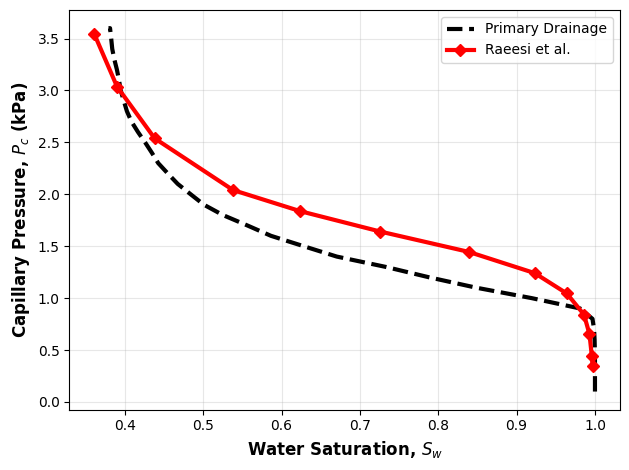

In [ ]:
##PLOT


import numpy as np
import matplotlib.pyplot as plt

# بارگذاری تاریخچه‌های شبکهٔ واقعی
hist_drain = np.load('history_drain_realBent.npy', allow_pickle=True).item()
#hist_imb = np.load('history_imb_realBent.npy', allow_pickle=True).item()
#hist_imb40 = np.load('history_imb_real_40.npy', allow_pickle=True).item()
#hist_imb60 = np.load('history_imb_real_60.npy', allow_pickle=True).item()

# به‌دست آوردن تعداد کل حفره‌های متصل (برای محاسبهٔ درصد)
# از آنجایی که state نهایی تمام حفره‌ها را شامل می‌شود، می‌توانیم از طول آرایهٔ trapped استفاده کنیم،
# ولی بهتر است مستقیماً تعداد حفره‌ها را از فایل state بخوانیم:
state_drain = np.load('state_drain_realBent.npy')
num_pores = len(state_drain)   # تعداد حفره‌های متصل (۹۵۲۴)

xRaee=[0.359,0.390,0.438,0.538,0.624,0.725,0.839,0.925,0.966,0.986,0.993,0.997,0.997]
yRaee=np.array([3.536,3.042,2.539,2.038,1.836,1.643,1.441,1.232,1.037,0.835,0.649,0.430,0.324])#*(.55)

xRaee2=np.array([0.998,0.998,0.995,0.988,0.968,0.926,0.841,0.727,0.625,0.537,0.439,0.388,0.360,0.342,0.325,0.315,0.297,0.282])
yRaee2=np.array([0.327, 0.413, 0.608, 0.791, 0.998, 1.205, 1.396, 1.604, 1.795, 2.003, 2.486, 3.003, 3.502, 3.967, 4.483, 4.965, 5.946, 6.944])#*.5

ximbRaee2=np.array([0.639, 0.623, 0.584,0.537,0.494, 0.450,0.394, 0.339,0.311,0.293,0.286,0.280])
yimbRaee2=np.array([0.419, 0.626, 0.798, 1.016, 1.213, 1.523, 2.001, 2.998, 4.002, 4.965, 5.966,6.961])#*.55

XraeeImb=[0.357,0.370,0.386,0.411,0.462,0.508,0.549,0.605,0.642,0.651]
YraeeImb=[3.543, 3.053, 2.531, 2.041, 1.535, 1.249, 1.037, 0.833, 0.637, 0.441]
XraeeDrain=[0.997,0.996,0.993,0.986,0.964,0.923,0.839,0.726,0.624,0.538,0.438,0.390,0.361]
YraeeDrain=[0.343, 0.441, 0.653, 0.841, 1.045, 1.241, 1.445, 1.641, 1.837, 2.041, 2.539, 3.037, 3.543]


plt.plot(hist_drain['Sw'], np.array(hist_drain['Pc'])*.001, 'k--', markersize=3, linewidth=3, label='Primary Drainage')
plt.plot(XraeeDrain, YraeeDrain, 'D-', color='red',linewidth=3, label='Raeesi et al.')
#plt.plot(hist_imb['Sw'], np.array(hist_imb['Pc'])*.001, 'b--', markersize=3, linewidth=3, label='Primary Imbibition')
#plt.plot(XraeeImb, YraeeImb, 'D-', color='green',linewidth=3, label='Raeesi et al.')


plt.xlabel('Water Saturation, $S_w$', fontsize=12,fontweight='bold')
plt.ylabel('Capillary Pressure, $P_c$ (kPa)', fontsize=12,fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
#plt.gca().invert_xaxis()   # اختیاری
plt.tight_layout()
plt.savefig('ImbComp.jpg', dpi=300, bbox_inches='tight')
# ============================
# Plot 1: Sw vs Pc (Hysteresis)
# ============================
#fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) Water saturation vs. Capillary pressure
#ax = axes[0]
#ax.plot(hist_drain['Sw'], np.array(hist_drain['Pc'])*0.001, '-', color='darkred', markersize=4, label='Primary Drainage')
#ax.plot(xRaee, yRaee, 'o-', color='darkblue', markersize=4, label='Raeesi')
#ax.plot(XraeeImb, YraeeImb, 'D-', color='blue', markersize=4, label='Raeesi')

#ax.plot(hist_imb['Sw'], np.array(hist_imb['Pc'])*.001, 'o-', color='red', markersize=4, label='Imbibition')
#ax.set_xlabel('Water Saturation, $S_w$')
#ax.set_ylabel('Capillary Pressure, $P_c$ (kPa)')
#ax.set_title('Hysteresis Loop: $S_w$ vs $P_c$ (Berea Network)')
#ax.legend(loc='best')
#ax.grid(True, alpha=0.3)
#ax.invert_xaxis()  # اختیاری

# (b) K_proxy vs Pc
#ax = axes[1]
#ax.plot(hist_drain['Sw'], np.array(hist_drain['Pc'])*0.001, '-', color='darkred', markersize=4, label='Primary Drainage')

#ax.plot(XraeeDrain, YraeeDrain, 'D-', color='blue', markersize=4, label='Raeesi')
#ax.plot(hist_imb20['Sw'], np.array(hist_imb20['Pc'])*0.001, '-', color='darkred', markersize=4, label='theta 20')
#ax.plot(hist_imb40['Sw'], np.array(hist_imb40['Pc'])*0.001, '-', color='green', markersize=4, label='theta 40')
#ax.plot(hist_imb60['Sw'], np.array(hist_imb60['Pc'])*0.001, '-', color='purple', markersize=4, label='theta 60')


#ax.plot(hist_drain['Pc'], hist_drain['K_proxy'], 's-', color='darkred', markersize=4, label='Drainage')
#ax.plot(hist_imb['Pc'], hist_imb['K_proxy'], 'o-', color='darkblue', markersize=4, label='Imbibition')
#ax.set_xlabel('$P_c$ (kPa)')
#ax.set_ylabel('$K_{\\rm proxy}$ (connected throat fraction)')
#ax.set_title('Transport Proxy')
#ax.legend(loc='best')
#ax.grid(True, alpha=0.3)

# (c) Trapped phase count
#ax = axes[2]
#ax.plot(hist_drain['Pc'], hist_drain['trapped'], 's-', color='darkred', markersize=4, label='Trapped Water (Drain)')
#ax.plot(hist_imb['Pc'], hist_imb['trapped'], 'o-', color='darkblue', markersize=4, label='Trapped Oil (Imb)')
#ax.set_xlabel('$P_c$ (Pa)')
#ax.set_ylabel('Number of Trapped Pores')
#ax.set_title('Trapping Evolution')
#ax.legend(loc='best')
#ax.grid(True, alpha=0.3)

#plt.suptitle('Capillary Pressure Driven Cyclic Displacement (Real Network)', fontweight='bold', y=1.02)
#plt.tight_layout()
#plt.show()

# چاپ درصدهای نهایی
#final_trapped_water = hist_drain['trapped'][-1]
#final_trapped_oil = hist_imb['trapped'][-1]
#print(f"Final trapped water after drainage: {final_trapped_water} pores ({final_trapped_water/num_pores*100:.1f}%)")
#print(f"Final trapped oil after imbibition:  {final_trapped_oil} pores ({final_trapped_oil/num_pores*100:.1f}%)")

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import heapq
import time
from scipy.stats import truncnorm

# ============================
# CONFIGURATION (Drainage – Regular Network)
# ============================
N = 10                           # ابعاد شبکه (N×N×N)
MAX_TIME_STEPS = 50
DP_PER_STEP = 1000               # kPa
Pc_max = 10000.0
CONVERGENCE_PATIENCE = 30       # تعداد پله‌های بدون تغییر برای توقف
SEED = 42

gamma_ow = 0.0515
Lambda_ref = 1.0                # ضریب ترپینگ (صفر = غیرفعال)
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)
TRAPPING_ON = (Lambda_ref > 0)

# ============================
# 1. ایجاد گره‌های واقعی (N×N×N)
# ============================
real_nodes = [(x, y, z) for z in range(N) for y in range(N) for x in range(N)]
n_pores = len(real_nodes)
idx_real = {coord: i for i, coord in enumerate(real_nodes)}

# شعاع حفره‌ها (توزیع لگ‌نرمال)
radii_log = np.random.normal(np.log(50e-6), 0.5, n_pores)
pore_radii = np.exp(radii_log)
pore_areas = 4 * np.pi * pore_radii**2
pore_vols = (4/3) * np.pi * pore_radii**3

# ============================
# 2. گره‌های سایه (مخازن آب و نفت)
# ============================
n_ghost_layer = N * N
idx_bottom_ghost = {}   # آب
idx_top_ghost = {}      # نفت
base_ghost = n_pores
for y in range(N):
    for x in range(N):
        idx_bottom_ghost[(x, y, -1)] = base_ghost + (y*N + x)
        idx_top_ghost[(x, y, N)] = base_ghost + n_ghost_layer + (y*N + x)
n_total = n_pores + 2 * n_ghost_layer

ghost_state = np.zeros(n_total, dtype=int)
for i in idx_bottom_ghost.values():
    ghost_state[i] = 0          # آب
for i in idx_top_ghost.values():
    ghost_state[i] = 1          # نفت

# شناسه‌های مخازن برای دسترسی سریع
BOTTOM_SOURCE = set(idx_bottom_ghost.values())
TOP_SOURCE = set(idx_top_ghost.values())

# ============================
# 3. ساخت گراف (یال‌های واقعی و سایه)
# ============================
edges = []                      # لیست یال‌ها (u, v) با u<v برای یکتایی
edge_throat_radius = []
edge_throat_area = []
adj = [[] for _ in range(n_pores)]

# یال‌های بین حفره‌های مجاور در جهت x, y, z
for (x, y, z) in real_nodes:
    u = idx_real[(x, y, z)]
    # همسایه‌های x و y (دوره‌ای)
    for dx, dy in [(1, 0), (0, 1)]:
        nx, ny = (x + dx) % N, (y + dy) % N
        v = idx_real[(nx, ny, z)]
        if u < v:
            edges.append((u, v))
            rh = 2 * pore_radii[u] * pore_radii[v] / (pore_radii[u] + pore_radii[v])
            edge_throat_radius.append(rh)
            edge_throat_area.append(np.pi * rh**2)
    # همسایه‌ی z (غیردوره‌ای)
    if z < N - 1:
        v = idx_real[(x, y, z + 1)]
        edges.append((u, v))
        rh = 2 * pore_radii[u] * pore_radii[v] / (pore_radii[u] + pore_radii[v])
        edge_throat_radius.append(rh)
        edge_throat_area.append(np.pi * rh**2)

num_edges = len(edges)

# پر کردن لیست مجاورت برای گره‌های واقعی
for u, v in edges:
    adj[u].append(v)
    adj[v].append(u)

# گراف کامل (شامل گره‌های سایه)
full_adj = [[] for _ in range(n_total)]
for u, v in edges:
    full_adj[u].append(v)
    full_adj[v].append(u)
# اتصال به مخزن آب (کف)
for y in range(N):
    for x in range(N):
        u_real = idx_real[(x, y, 0)]
        u_ghost = idx_bottom_ghost[(x, y, -1)]
        full_adj[u_real].append(u_ghost)
        full_adj[u_ghost].append(u_real)
# اتصال به مخزن نفت (سقف)
for y in range(N):
    for x in range(N):
        u_real = idx_real[(x, y, N-1)]
        u_ghost = idx_top_ghost[(x, y, N)]
        full_adj[u_real].append(u_ghost)
        full_adj[u_ghost].append(u_real)

# ============================
# 4. ترشوندگی (زوایای تماس)
# ============================
# برای حفظ نقشه فضایی با تغییر میانگین، از یک آرایه‌ی یکنواخت ثابت استفاده می‌کنیم
U = np.random.uniform(0, 1, n_pores)

def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=0, b_deg=180):
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    theta_rad = truncnorm.ppf(U, a_tr, b_tr,
                              loc=np.radians(mean_deg),
                              scale=np.radians(std_deg))
    return np.degrees(theta_rad)

# انتخاب میانگین دلخواه (مثلاً ۱۰۰ درجه برای میانه‌ترشوندگی)
theta_deg = generate_contact_angles_spatial_fixed(U, mean_deg=40, std_deg=10)
cos_theta = np.cos(np.deg2rad(theta_deg))
w2_scale = 1#np.mean(edge_throat_area) / np.mean(pore_areas)

# ============================
# 5. توابع کمکی برای اتصال و انرژی
# ============================

# --- وضعیت اتصال آب (فقط در صورت فعال بودن ترپینگ به‌روز می‌شود) ---
water_connected = np.zeros(n_pores, dtype=bool)

def recompute_water_connected():
    """BFS از مخزن آب برای یافتن حفره‌های آبی متصل."""
    visited = set()
    q = deque()
    for g in BOTTOM_SOURCE:
        if ghost_state[g] == 0:
            q.append(g)
            visited.add(g)
    while q:
        u = q.popleft()
        for v in full_adj[u]:
            if v not in visited and ghost_state[v] == 0:
                visited.add(v)
                q.append(v)
    # فقط گره‌های واقعی را برمی‌گردانیم
    return np.array([i in visited for i in range(n_pores)], dtype=bool)

def is_still_connected(v, blocked_node):
    """بررسی می‌کند که آیا از گرهٔ v مسیری به مخزن آب (بدون عبور از blocked_node) وجود دارد."""
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur in BOTTOM_SOURCE:
            return True, visited
        # اگر گرهٔ واقعی آب است و قبلاً متصل بوده، می‌توانیم زودتر برگردیم
        if cur < n_pores and water_connected[cur]:
            return True, visited
        for w in full_adj[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 0 and w not in visited:
                q.append(w)
    return False, visited

def get_min_throat_to_source(u, state, source_set, target_label=0):
    """کوچک‌ترین شعاع گلوگاه در مسیر از u به یکی از گره‌های source_set."""
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < n_pores and v < n_pores:
                    # پیدا کردن شعاع گلوگاه بین دو گره واقعی
                    # (برای سرعت، می‌توان از دیکشنری edge_map استفاده کرد، ولی اینجا ساده نوشته شده)
                    r_t = 1e-6
                    for idx_e, (a, b) in enumerate(edges):
                        if (a == cur and b == v) or (a == v and b == cur):
                            r_t = edge_throat_radius[idx_e]
                            break
                else:
                    r_t = 1e-3   # اتصال به مخزن با شعاع بزرگ
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii[u] * 0.5   # fallback

def compute_delta_J_drain(u, state, Pc):
    """تغییر انرژی برای تبدیل گره u از آب (۰) به نفت (۱)."""
    # جملهٔ ترشوندگی
    d_wett = w1_scale * gamma_ow * cos_theta[u] * pore_areas[u]
    # جملهٔ سطح مشترک
    d_iface = 0.0
    for v in adj[u]:
        t_v = state[v] if v < n_pores else ghost_state[v]
        delta = abs(1 - t_v) - abs(0 - t_v)
        # پیدا کردن مساحت گلوگاه
        area = 0.0
        for idx_e, (a, b) in enumerate(edges):
            if (a == u and b == v) or (a == v and b == u):
                area = edge_throat_area[idx_e]
                break
        else:
            area = np.pi * (min(pore_radii[u], 1e-6))**2
        d_iface += w2_scale * gamma_ow * area * delta

    # جملهٔ جریمه ترپینگ (فقط در صورت فعال بودن)
    penalty = 0.0
    if TRAPPING_ON:
        # بررسی می‌کنیم که آیا با برگرداندن این گره، گره‌های آبی محبوس می‌شوند؟
        # ابتدا لیست گره‌های آبی متصل قبل از تغییر
        connected_before = set(np.where(water_connected)[0])
        ghost_state[u] = 1
        # محاسبه اتصال جدید (می‌توان از BFS کامل استفاده کرد، ولی برای سرعت از is_still_connected استفاده می‌کنیم)
        trapped = False
        for v in adj[u]:
            if state[v] == 0 and water_connected[v]:
                conn, _ = is_still_connected(v, u)
                if not conn:
                    trapped = True
                    break
        ghost_state[u] = 0
        if trapped:
            r_min = get_min_throat_to_source(u, state, BOTTOM_SOURCE, target_label=0)
            penalty = Lambda_ref * gamma_ow * pore_areas[u] * (r_min / pore_radii[u])**2

    # جملهٔ فشار مویرگی
    d_pc = -beta_pc * Pc * pore_vols[u]
    return d_wett + d_iface + penalty + d_pc

# ============================
# 6. حالت اولیه (همه آب)
# ============================
state = np.zeros(n_pores, dtype=int)
ghost_state[:n_pores] = state

# محاسبه اتصال آب اولیه (همهٔ گره‌های آبی به مخزن آب متصل هستند چون همه آب هستند)
water_connected = recompute_water_connected()   # در این حالت همه true

# ساخت frontier: گره‌های آبی که حداقل یک همسایهٔ نفتی (مخزن نفت) دارند
frontier = set()
for u in range(n_pores):
    if state[u] == 0:
        if any(ghost_state[v] == 1 for v in full_adj[u]):
            frontier.add(u)

# ============================
# 7. حلقه اصلی با صف اولویت (heap)
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = 0.0
step_count = 0

def push_to_heap(u, pc):
    dJ = compute_delta_J_drain(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 0:
        push_to_heap(u, Pc)

while Pc <= Pc_max:
    # محاسبه K_proxy (نفت متصل به مخزن نفت)
    def compute_Kproxy_drain():
        visited = set()
        q = deque()
        for g in TOP_SOURCE:
            if ghost_state[g] == 1:
                q.append(g)
                visited.add(g)
        while q:
            u = q.popleft()
            for v in full_adj[u]:
                if v not in visited and ghost_state[v] == 1:
                    visited.add(v)
                    q.append(v)
        oil_connected = {i for i in visited if i < n_pores}
        if not oil_connected:
            return 0.0
        cnt = sum(1 for (u, v) in edges if u in oil_connected and v in oil_connected)
        return cnt / len(edges)

    # اگر heap خالی است یا کوچکترین dJ >= 0 باشد، فشار را افزایش بده
    if not heap or heap[0][0] >= 0.0:
        Pc += DP_PER_STEP
        if Pc > Pc_max:
            Pc = Pc_max
        step_count += 1

        Sw = np.mean(state == 0)
        Kp = compute_Kproxy_drain()
        trapped_water = np.sum((state == 0) & ~water_connected) if TRAPPING_ON else 0
        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_water)
        history['Pc'].append(Pc)
        print(f"Drain Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Water={trapped_water}")

        # بازسازی heap برای فشار جدید
        heap.clear()
        for u in frontier:
            if state[u] == 0:
                if TRAPPING_ON and not water_connected[u]:
                    continue
                push_to_heap(u, Pc)

        if Pc >= Pc_max and (not heap or heap[0][0] >= 0.0):
            print("Reached Pc_max with no more flips.")
            break
        continue

    # انتخاب گره با کمترین dJ
    dJ, u = heapq.heappop(heap)

    # اعتبارسنجی گره (ممکن است در بین زمان تغییر کرده باشد)
    if state[u] != 0:
        continue
    if TRAPPING_ON and not water_connected[u]:
        continue

    # اگر dJ منفی باشد، گره را به نفت تبدیل کن
    if dJ < 0.0:
        state[u] = 1
        ghost_state[u] = 1
        # به‌روزرسانی water_connected در صورت فعال بودن ترپینگ
        if TRAPPING_ON:
            water_connected[u] = False
            # گره‌های آبی را که ممکن است محبوس شده‌اند، علامت بزن
            for v in adj[u]:
                if state[v] == 0 and water_connected[v]:
                    conn, visited_set = is_still_connected(v, u)
                    if not conn:
                        for node in visited_set:
                            if node < n_pores:
                                water_connected[node] = False
        else:
            water_connected[u] = False   # مهم نیست، فقط برای یکپارچگی

        frontier.discard(u)

        # همسایه‌های جدید را به frontier اضافه کن
        for v in adj[u]:
            if state[v] == 0:
                frontier.add(v)
                if (not TRAPPING_ON) or water_connected[v]:
                    push_to_heap(v, Pc)

# ثبت نهایی (در صورتی که آخرین گام ثبت نشده باشد)
if step_count not in history['step'] or history['step'][-1] != step_count:
    Sw = np.mean(state == 0)
    Kp = compute_Kproxy_drain()
    trapped_water = np.sum((state == 0) & ~water_connected) if TRAPPING_ON else 0
    history['step'].append(step_count+1)
    history['Sw'].append(Sw)
    history['K_proxy'].append(Kp)
    history['trapped'].append(trapped_water)
    history['Pc'].append(Pc)

# ذخیره نتایج
np.save('state_drain.npy', state)
np.save('history_drain.npy', history)
print("Drainage on regular network finished.")

Drain Step  1 | Pc=1000.00 | Sw=1.000 | Kp=0.000 | Trapped Water=0
Drain Step  2 | Pc=2000.00 | Sw=0.999 | Kp=0.000 | Trapped Water=0
Drain Step  3 | Pc=3000.00 | Sw=0.988 | Kp=0.002 | Trapped Water=0
Drain Step  4 | Pc=4000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Drain Step  5 | Pc=5000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Drain Step  6 | Pc=6000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Drain Step  7 | Pc=7000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Drain Step  8 | Pc=8000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Drain Step  9 | Pc=9000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Drain Step 10 | Pc=10000.00 | Sw=0.000 | Kp=1.000 | Trapped Water=0
Reached Pc_max with no more flips.
Drainage on regular network finished.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# CONFIGURATION (Imbibition – Real Network)
# ============================
NETWORK_PATH = 'processed_network'
MAX_TIME_STEPS = 50
DP_PER_STEP = 100                 # kPa decrease per step
Pc_start = 3000.0                # Pc at which drainage ended (will be overridden by actual if needed)
Pc_min = 000.0
CONVERGENCE_PATIENCE = 260
SEED = 42

gamma_ow = 0.0515
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# ============================
# 1. Load drainage state
# ============================
state_drain = np.load('state_drain_real.npy')
# تعداد گره‌های متصل از روی طول state مشخص می‌شود
num_connected = len(state_drain)

# ============================
# 2. Reload network structure (same as drainage)
# ============================
# برای جلوگیری از تکرار کد، بخش بارگذاری و ساخت گراف را از drainage کپی می‌کنیم
# (در عمل بهتر است ماژول جداگانه باشد، اما فعلاً مستقل نگه می‌داریم)

def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores, "Mismatch in number of pores"

    inlet_pores_full = []
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:
                j = neighbor_orig - 1
                full_adj_all[i].append(j)

    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)
    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
full2new = {full: new for new, full in enumerate(connected_full)}

pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# Build graph (same as drainage)
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

# Reservoirs
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 3. Wettability (same angles as drainage – must be identical)
# ============================
from scipy.stats import truncnorm

# ۱. تنظیم Seed فقط یک بار برای تولید مقادیر پایه یکنواخت
#np.random.seed(42)
#num_pores = 10000  # تعداد حفره‌های شبکه شما
U = np.random.uniform(0, 1, net['num_pores'])

def generate_contact_angles(mode, num):
    if mode == 'mixed':
        mean_deg, std_deg = 80,15#81, 15
    else:
        mean_deg, std_deg = 40, 10
    a_deg, b_deg = 30, 150 #30, 150
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    return np.degrees(truncnorm.rvs(a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg), size=num))

np.random.seed(SEED)  # Reset seed to get identical angles
theta_deg_con = generate_contact_angles('mixed', num_connected)
cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
#theta_deg_con=theta_87[connected_full]
#cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = np.mean(edge_throat_area_con) / np.mean(pore_areas_con)

# ============================
# 4. Incremental connectivity for oil
# ============================
oil_connected = np.zeros(num_connected, dtype=bool)

def initialize_oil_connected():
    visited = set()
    q = deque([IDX_OIL_RES])
    visited.add(IDX_OIL_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 1:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        oil_connected[i] = (i in visited)

def is_still_connected_oil(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_OIL_RES:
            return True, visited
        if cur != v and cur < num_connected and oil_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 1 and w not in visited:
                q.append(w)
    return False, visited

def update_oil_connectivity_after_flip(u):
    for v in adj_con[u]:
        if state[v] == 1 and oil_connected[v]:
            connected, visited_set = is_still_connected_oil(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        oil_connected[node] = False

def get_min_throat_to_source_oil(u, state, source_set, target_label=1):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_imb(u, state, Pc):
    d_wett = -w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(0 - t_v) - abs(1 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_oil_connected = oil_connected.copy()
    ghost_state[u] = 0
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 1 and original_oil_connected[v]:
            connected, _ = is_still_connected_oil(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 1

    if triggers_trap:
        r_min = get_min_throat_to_source_oil(u, state, top_source_set, target_label=1)
        penalty = Lambda_ref * gamma_ow * pore_volumes_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = beta_pc * Pc * pore_volumes_con[u]  # note: positive sign for imbibition with decreasing Pc
    return d_wett + d_iface + penalty + d_pc

# ============================
# 5. Initialize with drainage state
# ============================
state = state_drain.copy()
ghost_state[:num_connected] = state

print(f"Initial Sw = {np.mean(state == 0):.3f}")

initialize_oil_connected()

# Frontier: oil nodes connected to top source and adjacent to water
frontier = set()
for u in range(num_connected):
    if state[u] == 1 and oil_connected[u]:
        if any(ghost_state[v] == 0 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 6. Optimized Imbibition Loop (priority queue, Pc decreasing)
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = Pc_start   # starting from drainage end pressure
step_count = 0

def push_to_heap_imb(u, pc):
    dJ = compute_delta_J_imb(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 1 and oil_connected[u]:
        push_to_heap_imb(u, Pc)

while Pc >= Pc_min:
    if not heap or heap[0][0] >= 0.0:
        Pc -= DP_PER_STEP
        if Pc < Pc_min:
            Pc = Pc_min
        step_count += 1

        # Record metrics
        Sw = np.mean(state == 0)
        # K_proxy: water cluster connected to bottom reservoir
        def compute_Kproxy_imb(st):
            visited = set()
            q = deque([IDX_WATER_RES])
            visited.add(IDX_WATER_RES)
            while q:
                u = q.popleft()
                for v in full_adj_con[u]:
                    if v not in visited and ghost_state[v] == 0:
                        visited.add(v)
                        q.append(v)
            water_conn = {i for i in visited if i < num_connected}
            if not water_conn:
                return 0.0
            cnt = sum(1 for (u,v) in edges_con if u in water_conn and v in water_conn)
            return cnt / len(edges_con)

        Kp = compute_Kproxy_imb(state)
        trapped_oil = np.sum((state == 1) & ~oil_connected)

        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_oil)
        history['Pc'].append(Pc)
        print(f"Imb Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Oil={trapped_oil}")

        # Rebuild heap with new Pc
        heap.clear()
        for u in frontier:
            if state[u] == 1 and oil_connected[u]:
                push_to_heap_imb(u, Pc)

        if Pc <= Pc_min:
            if not heap or heap[0][0] >= 0.0:
                print("Reached Pc_min with no more flips.")
                break
        continue

    dJ, u = heapq.heappop(heap)
    if state[u] != 1 or not oil_connected[u]:
        continue

    if dJ < 0.0:
        state[u] = 0
        ghost_state[u] = 0
        oil_connected[u] = False
        frontier.discard(u)
        update_oil_connectivity_after_flip(u)

        for v in adj_con[u]:
            if state[v] == 1:
                frontier.add(v)
                if oil_connected[v]:
                    push_to_heap_imb(v, Pc)

# Final save
#np.save('state_imb_real.npy', state)
#np.save('history_imb_real.npy', history)

np.save('state_imb_real.npy', state)
np.save('history_imb_real.npy', history)

print("Imbibition on real network finished.")

Initial Sw = 0.409
Imb Step  1 | Pc=2900.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  2 | Pc=2800.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  3 | Pc=2700.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  4 | Pc=2600.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  5 | Pc=2500.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  6 | Pc=2400.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  7 | Pc=2300.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  8 | Pc=2200.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step  9 | Pc=2100.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step 10 | Pc=2000.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step 11 | Pc=1900.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step 12 | Pc=1800.00 | Sw=0.409 | Kp=0.009 | Trapped Oil=0
Imb Step 13 | Pc=1700.00 | Sw=0.410 | Kp=0.009 | Trapped Oil=0
Imb Step 14 | Pc=1600.00 | Sw=0.411 | Kp=0.009 | Trapped Oil=0
Imb Step 15 | Pc=1500.00 | Sw=0.412 | Kp=0.009 | Trapped Oil=0
Imb Step 16 | Pc=1400.00 | Sw=0.413 

In [ ]:
import numpy as np
from sklearn.metrics import r2_score

# ==========================================
# داده‌های آزمایشگاهی (آبی) - از جدول شما
# ==========================================
sw_exp=[0.998,0.998,0.995,0.988,0.968,0.926,0.841,0.727,0.625,0.537,0.439,0.388,0.360,0.342,0.325,0.315,0.297,0.282]
pc_exp=np.array([0.327, 0.413, 0.608, 0.791, 0.998, 1.205, 1.396, 1.604, 1.795, 2.003, 2.486, 3.003, 3.502, 3.967, 4.483, 4.965, 5.946, 6.944])#*.5


#sw_exp = np.array([0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00])
#pc_exp = np.array([7.0, 5.0, 3.2, 2.8, 2.4, 2.0, 1.9, 1.8, 1.7, 1.6, 1.5, 1.4, 1.3, 1.2, 0.8])  # Pa

# ==========================================
# داده‌های شبیه‌سازی (قرمز)
# ==========================================
sw_sim = np.array(hist_drain['Sw'])
pc_sim = np.array(hist_drain['Pc']) * 0.001  # تبدیل به Pa (چون kPa * 0.001 = Pa)

# نکته مهم: داده‌های تخلیه معمولاً Sw نزولی هستند (از ۱ به سمت پایین).
# برای درون‌یابی (interpolation)، آرایه باید صعودی باشد، پس برعکسش می‌کنیم:
sw_sim_sorted = sw_sim[::-1]
pc_sim_sorted = pc_sim[::-1]

# درون‌یابی فشار شبیه‌سازی در نقاط اشباع آزمایشگاهی
pc_sim_interp = np.interp(sw_exp, sw_sim_sorted, pc_sim_sorted)

# ==========================================
# محاسبه معیارهای خطا
# ==========================================
rmse = np.sqrt(np.mean((pc_exp - pc_sim_interp)**2))
mae = np.mean(np.abs(pc_exp - pc_sim_interp))
r2 = r2_score(pc_exp, pc_sim_interp)

# درصد خطای مطلق (MAPE) - فقط برای نقاطی که Pc_exp > 0 است (تا تقسیم بر صفر نشود)
mask = pc_exp > 0
mape = np.mean(np.abs((pc_exp[mask] - pc_sim_interp[mask]) / pc_exp[mask])) * 100

# ==========================================
# چاپ نتایج در کنسول
# ==========================================
print("========== NUMERICAL COMPARISON ==========")
print(f"Root Mean Square Error (RMSE) : {rmse:.3f}  kPa")
print(f"Mean Absolute Error (MAE)     : {mae:.3f}  kPa")
print(f"Coefficient of Determination (R²) : {r2:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f} %")
print("===========================================")

========== NUMERICAL COMPARISON ==========
Root Mean Square Error (RMSE) : 1.120  kPa
Mean Absolute Error (MAE)     : 0.672  kPa
Coefficient of Determination (R²) : 0.6640
Mean Absolute Percentage Error (MAPE): 30.50 %


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os

# ============================
# CONFIGURATION (Drainage – Real Network)
# ============================
NETWORK_PATH = 'processed_network'   # پوشهٔ حاوی processed_network.npz
MAX_TIME_STEPS = 50
DP_PER_STEP = 1000                    # kPa
Pc_max = 90000.0
CONVERGENCE_PATIENCE = 60
SEED = 42

gamma_ow = 0.0515
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# ============================
# 1. بارگذاری داده‌های خام و محاسبهٔ حفره‌های متصل
# ============================
def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    # الف) خواندن processed_network.npz
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    # بازسازی neighbor_list (شناسه‌های اصلی) برای همهٔ حفره‌ها
    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    # ب) خواندن node1.dat برای یافتن حفره‌های ورودی/خروجی
    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores, "تعداد حفره‌ها در node1.dat با processed_network مغایرت دارد"

    inlet_pores_full = []   # اندیس ۰-محور در آرایهٔ کامل
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    # ج) ساخت گراف کامل (فقط حفره‌ها، بدون گلوگاه‌ها) برای BFS
    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:  # فقط حفره‌های واقعی
                j = neighbor_orig - 1  # شناسه اصلی به اندیس ۰-محور
                full_adj_all[i].append(j)

    # د) BFS از همهٔ حفره‌های ورودی و خروجی برای یافتن حفره‌های متصل به مخازن
    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())   # <-- اصلاح شده برای جلوگیری از خطای float
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)  # اندیس‌های ۰-محور حفره‌های متصل
    print(f"تعداد حفره‌های متصل به مخازن: {len(connected_full)} (از {num_pores})")

    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')

# حفره‌های متصل
connected_full = net['connected_full']
num_connected = len(connected_full)
full2new = {full: new for new, full in enumerate(connected_full)}

# ویژگی‌های حفره‌های متصل
pore_coords_con = net['pore_coords'][connected_full]
pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# ============================
# 2. ساخت گراف و گلوگاه‌ها برای بخش متصل
# ============================
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

# ============================
# 3. گره‌های مخزن (آب و نفت)
# ============================
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

# اتصال ورودی‌ها به مخزن آب
for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

# اتصال خروجی‌ها به مخزن نفت
for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 4. ترشوندگی
# ============================
#def generate_contact_angles(mode, num):
#    if mode == 'mixed':
#        mean_deg, std_deg = 40, 10
#    else:
#        mean_deg, std_deg = 40, 10
#    a_deg, b_deg = 30, 150
#    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
#    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
#    return np.degrees(truncnorm.rvs(a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg), size=num))

#import numpy as np
from scipy.stats import truncnorm

# ۱. تنظیم Seed فقط یک بار برای تولید مقادیر پایه یکنواخت
#np.random.seed(42)
#num_pores = 10000  # تعداد حفره‌های شبکه شما
U = np.random.uniform(0, 1, net['num_pores'])

def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=0, b_deg=180):
    """
    تولید توزیع زاویه تماس با حفظ نقشه فضایی (Spatial Map)
    """
    # محاسبه مرزهای بریده‌شده برای توزیع نرمال استاندارد
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)

    # استفاده از ppf برای تبدیل مقادیر یکنواخت به زوایای تماس بریده‌شده
    # این کار تضمین می‌کند که ترتیب حفره‌ها با تغییر میانگین عوض نمی‌شود
    theta_rad = truncnorm.ppf(U, a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg))
    return np.degrees(theta_rad)

# ۲. حالا می‌توانید مانور روی میانگین را با اطمینان کامل علمی انجام دهید:
theta_40  = generate_contact_angles_spatial_fixed(U, mean_deg=40,  std_deg=10)
theta_80  = generate_contact_angles_spatial_fixed(U, mean_deg=80,  std_deg=10)
theta_100 = generate_contact_angles_spatial_fixed(U, mean_deg=100, std_deg=10)
theta_120 = generate_contact_angles_spatial_fixed(U, mean_deg=120, std_deg=10)
theta_140 = generate_contact_angles_spatial_fixed(U, mean_deg=140, std_deg=10)

theta_deg_con=theta_140
#theta_deg_con = generate_contact_angles('mixed', num_connected)
cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = np.mean(edge_throat_area_con) / np.mean(pore_areas_con)

# ============================
# 5. توابع اتصال افزایشی (برای آب)
# ============================
water_connected = np.zeros(num_connected, dtype=bool)

def initialize_water_connected():
    visited = set()
    q = deque([IDX_WATER_RES])
    visited.add(IDX_WATER_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 0:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        water_connected[i] = (i in visited)

def is_still_connected(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_WATER_RES:
            return True, visited
        if cur != v and cur < num_connected and water_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 0 and w not in visited:
                q.append(w)
    return False, visited

def update_water_connectivity_after_flip(u):
    for v in adj_con[u]:
        if state[v] == 0 and water_connected[v]:
            connected, visited_set = is_still_connected(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        water_connected[node] = False

def get_min_throat_to_source(u, state, source_set, target_label=0):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_drain(u, state, Pc):
    d_wett = w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(1 - t_v) - abs(0 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_connected = water_connected.copy()
    ghost_state[u] = 1
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 0 and original_connected[v]:
            connected, _ = is_still_connected(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 0

    if triggers_trap:
        r_min = get_min_throat_to_source(u, state, bottom_source_set, target_label=0)
        penalty = Lambda_ref * gamma_ow * pore_volumes_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = -beta_pc * Pc * pore_volumes_con[u]
    return d_wett + d_iface + penalty + d_pc

# ============================
# 6. حالت اولیه (همه آب)
# ============================
state = np.zeros(num_connected, dtype=int)
ghost_state[:num_connected] = state

initialize_water_connected()

frontier = set()
for u in range(num_connected):
    if state[u] == 0 and water_connected[u]:
        if any(ghost_state[v] == 1 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 7. حلقهٔ اصلی تخلیه
# ============================
import heapq

# ... (کد قبلی تا قبل از حلقه اصلی بدون تغییر)

# ============================
# 7. حلقه اصلی بهینه با صف اولویت
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = 0.0
step_count = 0

# تابع کمکی برای محاسبه ΔJ و اضافه به صف
def push_to_heap(u, pc):
    dJ = compute_delta_J_drain(u, state, pc)
    heapq.heappush(heap, (dJ, u))

# ساخت صف اولیه از frontier
heap = []
for u in frontier:
    if state[u] == 0 and water_connected[u]:
        push_to_heap(u, Pc)

while Pc <= Pc_max:
    def compute_Kproxy_drain(st):
        visited = set()
        q = deque([IDX_OIL_RES])
        visited.add(IDX_OIL_RES)
        while q:
            u = q.popleft()
            for v in full_adj_con[u]:
                if v not in visited and ghost_state[v] == 1:
                    visited.add(v)
                    q.append(v)
        oil_connected = {i for i in visited if i < num_connected}
        if not oil_connected:
            return 0.0
        cnt = sum(1 for (u,v) in edges_con if u in oil_connected and v in oil_connected)
        return cnt / len(edges_con)    # اگر صف خالی است یا کمترین ΔJ >= 0، فشار را افزایش بده
    if not heap or heap[0][0] >= 0.0:
        Pc += DP_PER_STEP
        if Pc > Pc_max:
            Pc = Pc_max
        step_count += 1

        # ثبت تاریخچه
        Sw = np.mean(state == 0)
        Kp = compute_Kproxy_drain(state)
        trapped_water = np.sum((state == 0) & ~water_connected)
        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_water)
        history['Pc'].append(Pc)
        print(f"Drain Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Water={trapped_water}")

        # بازسازی صف با فشار جدید
        heap.clear()
        for u in frontier:
            if state[u] == 0 and water_connected[u]:
                push_to_heap(u, Pc)

        if Pc >= Pc_max:
            if not heap or heap[0][0] >= 0.0:
                print("Reached Pc_max with no more flips.")
                break
        continue

    # برداشتن کمترین ΔJ
    dJ, u = heapq.heappop(heap)

    # بررسی اعتبار گره (ممکن است در این فاصله تغییر کرده باشد)
    if state[u] != 0 or not water_connected[u]:
        continue

    # اگر ΔJ هنوز منفی است، فلیپ کن
    if dJ < 0.0:
        state[u] = 1
        ghost_state[u] = 1
        water_connected[u] = False
        frontier.discard(u)
        update_water_connectivity_after_flip(u)

        # اضافه کردن همسایگان جدید به frontier و صف
        for v in adj_con[u]:
            if state[v] == 0:
                frontier.add(v)
                if water_connected[v]:
                    push_to_heap(v, Pc)
    # اگر dJ >= 0 باشد، گره را دور می‌اندازیم (با افزایش فشار دوباره محاسبه می‌شود)

# ثبت نهایی در صورت نیاز
if step_count not in history['step'] or history['step'][-1] != step_count:
    Sw = np.mean(state == 0)
    Kp = compute_Kproxy_drain(state)
    trapped_water = np.sum((state == 0) & ~water_connected)
    history['step'].append(step_count+1)
    history['Sw'].append(Sw)
    history['K_proxy'].append(Kp)
    history['trapped'].append(trapped_water)
    history['Pc'].append(Pc)

np.save('state_drain_real.npy', state)
np.save('history_drain_real.npy', history)
print("Drainage on real network finished.")

تعداد حفره‌های متصل به مخازن: 3373 (از 3393)
Drain Step  1 | Pc=1000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  2 | Pc=2000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  3 | Pc=3000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  4 | Pc=4000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  5 | Pc=5000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  6 | Pc=6000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  7 | Pc=7000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  8 | Pc=8000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step  9 | Pc=9000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step 10 | Pc=10000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step 11 | Pc=11000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step 12 | Pc=12000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step 13 | Pc=13000.00 | Sw=0.330 | Kp=0.719 | Trapped Water=1109
Drain Step 14 | Pc=14000.00 | Sw=0.330 | 

#CurveScanning

##Imbibition

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# CONFIGURATION (Imbibition – Real Network)
# ============================
NETWORK_PATH = 'processed_network'
SNAPSHOT_FILE = 'state_drain_real.npy'
MAX_TIME_STEPS = 50
DP_PER_STEP = 20                 # kPa decrease per step
Pc_start = 760.0                # Pc at which drainage ended (will be overridden by actual if needed)
Pc_min = 0.0
CONVERGENCE_PATIENCE = 60
SEED = 42

gamma_ow = 0.0515
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# ============================
# 1. Load drainage state
# ============================
state_drain = np.load(SNAPSHOT_FILE)
# تعداد گره‌های متصل از روی طول state مشخص می‌شود
num_connected = len(state_drain)

# ============================
# 2. Reload network structure (same as drainage)
# ============================
# برای جلوگیری از تکرار کد، بخش بارگذاری و ساخت گراف را از drainage کپی می‌کنیم
# (در عمل بهتر است ماژول جداگانه باشد، اما فعلاً مستقل نگه می‌داریم)

def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores, "Mismatch in number of pores"

    inlet_pores_full = []
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:
                j = neighbor_orig - 1
                full_adj_all[i].append(j)

    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)
    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
full2new = {full: new for new, full in enumerate(connected_full)}

pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# Build graph (same as drainage)
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

# Reservoirs
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 3. Wettability (same angles as drainage – must be identical)
# ============================
def generate_contact_angles(mode, num):
    if mode == 'mixed':
        mean_deg, std_deg = 80,15#81, 15
    else:
        mean_deg, std_deg = 40, 10
    a_deg, b_deg = 30, 150 #30, 150
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    return np.degrees(truncnorm.rvs(a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg), size=num))

np.random.seed(SEED)  # Reset seed to get identical angles
theta_deg_con = generate_contact_angles('mixed', num_connected)
cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = 1#np.mean(edge_throat_area_con) / np.mean(pore_areas_con)

# ============================
# 4. Incremental connectivity for oil
# ============================
oil_connected = np.zeros(num_connected, dtype=bool)

def initialize_oil_connected():
    visited = set()
    q = deque([IDX_OIL_RES])
    visited.add(IDX_OIL_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 1:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        oil_connected[i] = (i in visited)

def is_still_connected_oil(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_OIL_RES:
            return True, visited
        if cur != v and cur < num_connected and oil_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 1 and w not in visited:
                q.append(w)
    return False, visited

def update_oil_connectivity_after_flip(u):
    for v in adj_con[u]:
        if state[v] == 1 and oil_connected[v]:
            connected, visited_set = is_still_connected_oil(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        oil_connected[node] = False

def get_min_throat_to_source_oil(u, state, source_set, target_label=1):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_imb(u, state, Pc):
    d_wett = -w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(0 - t_v) - abs(1 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_oil_connected = oil_connected.copy()
    ghost_state[u] = 0
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 1 and original_oil_connected[v]:
            connected, _ = is_still_connected_oil(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 1

    if triggers_trap:
        r_min = get_min_throat_to_source_oil(u, state, top_source_set, target_label=1)
        penalty = Lambda_ref * gamma_ow * pore_areas_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = beta_pc * Pc * pore_volumes_con[u]  # note: positive sign for imbibition with decreasing Pc
    return d_wett + d_iface + penalty + d_pc

# ============================
# 5. Initialize with drainage state
# ============================
state = state_drain.copy()
ghost_state[:num_connected] = state

print(f"Initial Sw = {np.mean(state == 0):.3f}")

initialize_oil_connected()

# Frontier: oil nodes connected to top source and adjacent to water
frontier = set()
for u in range(num_connected):
    if state[u] == 1 and oil_connected[u]:
        if any(ghost_state[v] == 0 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 6. Optimized Imbibition Loop (priority queue, Pc decreasing)
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = Pc_start   # starting from drainage end pressure
step_count = 0

def push_to_heap_imb(u, pc):
    dJ = compute_delta_J_imb(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 1 and oil_connected[u]:
        push_to_heap_imb(u, Pc)

while Pc >= Pc_min:
    if not heap or heap[0][0] >= 0.0:
        Pc -= DP_PER_STEP
        if Pc < Pc_min:
            Pc = Pc_min
        step_count += 1

        # Record metrics
        Sw = np.mean(state == 0)
        # K_proxy: water cluster connected to bottom reservoir
        def compute_Kproxy_imb(st):
            visited = set()
            q = deque([IDX_WATER_RES])
            visited.add(IDX_WATER_RES)
            while q:
                u = q.popleft()
                for v in full_adj_con[u]:
                    if v not in visited and ghost_state[v] == 0:
                        visited.add(v)
                        q.append(v)
            water_conn = {i for i in visited if i < num_connected}
            if not water_conn:
                return 0.0
            cnt = sum(1 for (u,v) in edges_con if u in water_conn and v in water_conn)
            return cnt / len(edges_con)

        Kp = compute_Kproxy_imb(state)
        trapped_oil = np.sum((state == 1) & ~oil_connected)

        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_oil)
        history['Pc'].append(Pc)
        print(f"Imb Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Oil={trapped_oil}")

        # Rebuild heap with new Pc
        heap.clear()
        for u in frontier:
            if state[u] == 1 and oil_connected[u]:
                push_to_heap_imb(u, Pc)

        if Pc <= Pc_min:
            if not heap or heap[0][0] >= 0.0:
                print("Reached Pc_min with no more flips.")
                break
        continue

    dJ, u = heapq.heappop(heap)
    if state[u] != 1 or not oil_connected[u]:
        continue

    if dJ < 0.0:
        state[u] = 0
        ghost_state[u] = 0
        oil_connected[u] = False
        frontier.discard(u)
        update_oil_connectivity_after_flip(u)

        for v in adj_con[u]:
            if state[v] == 1:
                frontier.add(v)
                if oil_connected[v]:
                    push_to_heap_imb(v, Pc)

# Final save
#np.save('state_imb_150.npy', state)
#np.save('history_imb_150.npy', history)
np.save(f'state_imb_{int(Pc_start)}.npy', state)
# np.save('history_imb_real.npy', history) →
np.save(f'history_imb_{int(Pc_start)}.npy', history)

print("Imbibition on real network finished.")

Initial Sw = 0.440
Imb Step  1 | Pc=740.00 | Sw=0.440 | Kp=0.025 | Trapped Oil=0
Imb Step  2 | Pc=720.00 | Sw=0.441 | Kp=0.025 | Trapped Oil=0
Imb Step  3 | Pc=700.00 | Sw=0.442 | Kp=0.026 | Trapped Oil=0
Imb Step  4 | Pc=680.00 | Sw=0.443 | Kp=0.026 | Trapped Oil=0
Imb Step  5 | Pc=660.00 | Sw=0.444 | Kp=0.026 | Trapped Oil=0
Imb Step  6 | Pc=640.00 | Sw=0.445 | Kp=0.026 | Trapped Oil=0
Imb Step  7 | Pc=620.00 | Sw=0.446 | Kp=0.026 | Trapped Oil=0
Imb Step  8 | Pc=600.00 | Sw=0.447 | Kp=0.026 | Trapped Oil=0
Imb Step  9 | Pc=580.00 | Sw=0.448 | Kp=0.026 | Trapped Oil=0
Imb Step 10 | Pc=560.00 | Sw=0.450 | Kp=0.027 | Trapped Oil=2
Imb Step 11 | Pc=540.00 | Sw=0.451 | Kp=0.027 | Trapped Oil=2
Imb Step 12 | Pc=520.00 | Sw=0.453 | Kp=0.027 | Trapped Oil=2
Imb Step 13 | Pc=500.00 | Sw=0.454 | Kp=0.027 | Trapped Oil=2
Imb Step 14 | Pc=480.00 | Sw=0.456 | Kp=0.028 | Trapped Oil=4
Imb Step 15 | Pc=460.00 | Sw=0.458 | Kp=0.029 | Trapped Oil=5
Imb Step 16 | Pc=440.00 | Sw=0.462 | Kp=0.030 | Tra

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# CONFIGURATION (Imbibition – Real Network)
# ============================
NETWORK_PATH = 'processed_network'
MAX_TIME_STEPS = 50
DP_PER_STEP = 50                 # kPa decrease per step
Pc_start = 2000.0                # Pc at which drainage ended (will be overridden by actual if needed)
Pc_min = 000.0
CONVERGENCE_PATIENCE = 60
SEED = 42

gamma_ow = 0.0515
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# ============================
# 1. Load drainage state
# ============================
state_drain = np.load('state_drain_real.npy')
# تعداد گره‌های متصل از روی طول state مشخص می‌شود
num_connected = len(state_drain)

# ============================
# 2. Reload network structure (same as drainage)
# ============================
# برای جلوگیری از تکرار کد، بخش بارگذاری و ساخت گراف را از drainage کپی می‌کنیم
# (در عمل بهتر است ماژول جداگانه باشد، اما فعلاً مستقل نگه می‌داریم)

def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores, "Mismatch in number of pores"

    inlet_pores_full = []
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:
                j = neighbor_orig - 1
                full_adj_all[i].append(j)

    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)
    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
full2new = {full: new for new, full in enumerate(connected_full)}

pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# Build graph (same as drainage)
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

# Reservoirs
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 3. Wettability (same angles as drainage – must be identical)
# ============================
def generate_contact_angles(mode, num):
    if mode == 'mixed':
        mean_deg, std_deg = 80,15#81, 15
    else:
        mean_deg, std_deg = 40, 10
    a_deg, b_deg = 30, 150 #30, 150
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    return np.degrees(truncnorm.rvs(a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg), size=num))

np.random.seed(SEED)  # Reset seed to get identical angles
theta_deg_con = generate_contact_angles('mixed', num_connected)
cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = np.mean(edge_throat_area_con) / np.mean(pore_areas_con)

# ============================
# 4. Incremental connectivity for oil
# ============================
oil_connected = np.zeros(num_connected, dtype=bool)

def initialize_oil_connected():
    visited = set()
    q = deque([IDX_OIL_RES])
    visited.add(IDX_OIL_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 1:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        oil_connected[i] = (i in visited)

def is_still_connected_oil(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_OIL_RES:
            return True, visited
        if cur != v and cur < num_connected and oil_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 1 and w not in visited:
                q.append(w)
    return False, visited

def update_oil_connectivity_after_flip(u):
    for v in adj_con[u]:
        if state[v] == 1 and oil_connected[v]:
            connected, visited_set = is_still_connected_oil(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        oil_connected[node] = False

def get_min_throat_to_source_oil(u, state, source_set, target_label=1):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_imb(u, state, Pc):
    d_wett = -w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(0 - t_v) - abs(1 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_oil_connected = oil_connected.copy()
    ghost_state[u] = 0
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 1 and original_oil_connected[v]:
            connected, _ = is_still_connected_oil(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 1

    if triggers_trap:
        r_min = get_min_throat_to_source_oil(u, state, top_source_set, target_label=1)
        penalty = Lambda_ref * gamma_ow * pore_volumes_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = beta_pc * Pc * pore_volumes_con[u]  # note: positive sign for imbibition with decreasing Pc
    return d_wett + d_iface + penalty + d_pc

# ============================
# 5. Initialize with drainage state
# ============================
state = state_drain.copy()
ghost_state[:num_connected] = state

print(f"Initial Sw = {np.mean(state == 0):.3f}")

initialize_oil_connected()

# Frontier: oil nodes connected to top source and adjacent to water
frontier = set()
for u in range(num_connected):
    if state[u] == 1 and oil_connected[u]:
        if any(ghost_state[v] == 0 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 6. Optimized Imbibition Loop (priority queue, Pc decreasing)
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = Pc_start   # starting from drainage end pressure
step_count = 0

def push_to_heap_imb(u, pc):
    dJ = compute_delta_J_imb(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 1 and oil_connected[u]:
        push_to_heap_imb(u, Pc)

while Pc >= Pc_min:
    if not heap or heap[0][0] >= 0.0:
        Pc -= DP_PER_STEP
        if Pc < Pc_min:
            Pc = Pc_min
        step_count += 1

        # Record metrics
        Sw = np.mean(state == 0)
        # K_proxy: water cluster connected to bottom reservoir
        def compute_Kproxy_imb(st):
            visited = set()
            q = deque([IDX_WATER_RES])
            visited.add(IDX_WATER_RES)
            while q:
                u = q.popleft()
                for v in full_adj_con[u]:
                    if v not in visited and ghost_state[v] == 0:
                        visited.add(v)
                        q.append(v)
            water_conn = {i for i in visited if i < num_connected}
            if not water_conn:
                return 0.0
            cnt = sum(1 for (u,v) in edges_con if u in water_conn and v in water_conn)
            return cnt / len(edges_con)

        Kp = compute_Kproxy_imb(state)
        trapped_oil = np.sum((state == 1) & ~oil_connected)

        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_oil)
        history['Pc'].append(Pc)
        print(f"Imb Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Oil={trapped_oil}")

        # Rebuild heap with new Pc
        heap.clear()
        for u in frontier:
            if state[u] == 1 and oil_connected[u]:
                push_to_heap_imb(u, Pc)

        if Pc <= Pc_min:
            if not heap or heap[0][0] >= 0.0:
                print("Reached Pc_min with no more flips.")
                break
        continue

    dJ, u = heapq.heappop(heap)
    if state[u] != 1 or not oil_connected[u]:
        continue

    if dJ < 0.0:
        state[u] = 0
        ghost_state[u] = 0
        oil_connected[u] = False
        frontier.discard(u)
        update_oil_connectivity_after_flip(u)

        for v in adj_con[u]:
            if state[v] == 1:
                frontier.add(v)
                if oil_connected[v]:
                    push_to_heap_imb(v, Pc)

# Final save
#np.save('state_imb_real.npy', state)
#np.save('history_imb_real.npy', history)

np.save('state_imbForce_real.npy', state)
np.save('history_imbForce_real.npy', history)

print("Imbibition on real network finished.")

FileNotFoundError: [Errno 2] No such file or directory: 'state_drain_real.npy'

##Second drainage

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# USER INPUTS FOR SECONDARY DRAINAGE
# ============================
INITIAL_STATE_FILE = 'state_imb_150.npy'   # ← فایل وضعیت نهایی تزریق از ۱۰۰۰
PC_START = 0.0                               # فشار آغازین تخلیه (معمولاً ۰)
PC_MAX = 2000.0                               # فشار نهایی تخلیه
CHECKPOINT_PRESSURES = []                    # می‌توانید ذخیره snapshot را خالی بگذارید

# سایر تنظیمات
NETWORK_PATH = 'processed_network'
MAX_TIME_STEPS = 2000
DP_FINE = 20
FINE_DP_THRESHOLD = 200.0
DP_COARSE = 20
CONVERGENCE_PATIENCE = 60
SEED = 42

gamma_ow = 0.0515
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

np.random.seed(SEED)

# ============================
# 1. بارگذاری شبکه (همانند قبل)
# ============================
def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores

    inlet_pores_full = []
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:
                j = neighbor_orig - 1
                full_adj_all[i].append(j)

    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)
    print(f"تعداد حفره‌های متصل به مخازن: {len(connected_full)} (از {num_pores})")
    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }   # برگرداندن دیکشنری مشابه قبل

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
num_connected = len(connected_full)
full2new = {full: new for new, full in enumerate(connected_full)}
pore_coords_con = net['pore_coords'][connected_full]
pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# ============================
# 2. ساخت گراف (بدون تغییر)
# ============================
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}
throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)
num_edges_con = len(edges_con)

# ============================
# 3. مخازن (بدون تغییر)
# ============================
IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

ghost_state = np.zeros(num_total, dtype=int)
ghost_state[IDX_WATER_RES] = 0
ghost_state[IDX_OIL_RES] = 1

full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)
for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)
for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 4. ترشوندگی (بدون تغییر)
# ============================
def generate_contact_angles(mode, num):
    if mode == 'mixed':
        mean_deg, std_deg = 80, 15
    else:
        mean_deg, std_deg = 40, 10
    a_deg, b_deg = 30, 150
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    return np.degrees(truncnorm.rvs(a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg), size=num))

theta_deg_con = generate_contact_angles('mixed', num_connected)
cos_theta_con = np.cos(np.deg2rad(theta_deg_con))
w2_scale_con = 1#np.mean(edge_throat_area_con) / np.mean(pore_areas_con)

# ============================
# 5. توابع اتصال (بدون تغییر)
# ============================
water_connected = np.zeros(num_connected, dtype=bool)

def initialize_water_connected():
    visited = set()
    q = deque([IDX_WATER_RES])
    visited.add(IDX_WATER_RES)
    while q:
        u = q.popleft()
        for v in full_adj_con[u]:
            if v not in visited and ghost_state[v] == 0:
                visited.add(v)
                q.append(v)
    for i in range(num_connected):
        water_connected[i] = (i in visited)

def is_still_connected(v, blocked_node):
    visited = set()
    q = deque([v])
    while q:
        cur = q.popleft()
        if cur in visited:
            continue
        visited.add(cur)
        if cur == IDX_WATER_RES:
            return True, visited
        if cur != v and cur < num_connected and water_connected[cur]:
            return True, visited
        for w in full_adj_con[cur]:
            if w == blocked_node:
                continue
            if ghost_state[w] == 0 and w not in visited:
                q.append(w)
    return False, visited

def update_water_connectivity_after_flip(u):
    for v in adj_con[u]:
        if state[v] == 0 and water_connected[v]:
            connected, visited_set = is_still_connected(v, u)
            if not connected:
                for node in visited_set:
                    if node < num_connected:
                        water_connected[node] = False

def get_min_throat_to_source(u, state, source_set, target_label=0):
    visited = {u}
    q = deque([(u, float('inf'))])
    while q:
        cur, r_min = q.popleft()
        if cur in source_set:
            return r_min
        for v in full_adj_con[cur]:
            if v not in visited and ghost_state[v] == target_label:
                if cur < num_connected and v < num_connected:
                    key = (min(cur, v), max(cur, v))
                    r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                else:
                    r_t = 1e-3
                new_min = min(r_min, r_t)
                visited.add(v)
                q.append((v, new_min))
    return pore_radii_con[u] * 0.5

def compute_delta_J_drain(u, state, Pc):
    d_wett = w1_scale * gamma_ow * cos_theta_con[u] * pore_areas_con[u]
    d_iface = 0.0
    for v in adj_con[u]:
        t_v = state[v] if v < num_connected else ghost_state[v]
        delta = abs(1 - t_v) - abs(0 - t_v)
        key = (min(u, v), max(u, v))
        area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
        d_iface += w2_scale_con * gamma_ow * area * delta

    penalty = 0.0
    original_connected = water_connected.copy()
    ghost_state[u] = 1
    triggers_trap = False
    for v in adj_con[u]:
        if state[v] == 0 and original_connected[v]:
            connected, _ = is_still_connected(v, u)
            if not connected:
                triggers_trap = True
                break
    ghost_state[u] = 0

    if triggers_trap:
        r_min = get_min_throat_to_source(u, state, bottom_source_set, target_label=0)
        penalty = Lambda_ref * gamma_ow * pore_areas_con[u] * (r_min / pore_radii_con[u])**2

    d_pc = -beta_pc * Pc * pore_volumes_con[u]
    return d_wett + d_iface + penalty + d_pc

# ============================
# 6. بارگذاری وضعیت اولیه (از فایل)
# ============================
state = np.load(INITIAL_STATE_FILE)
ghost_state[:num_connected] = state

print(f"Initial Sw = {np.mean(state == 0):.3f}")

initialize_water_connected()

# Frontier: گره‌های آبی متصل به منبع که همسایهٔ نفت دارند
frontier = set()
for u in range(num_connected):
    if state[u] == 0 and water_connected[u]:
        if any(ghost_state[v] == 1 for v in full_adj_con[u]):
            frontier.add(u)

# ============================
# 7. حلقهٔ اصلی تخلیه
# ============================
history = {'step': [], 'Sw': [], 'K_proxy': [], 'trapped': [], 'Pc': []}
Pc = PC_START
step_count = 0
saved_checkpoints = set()

def push_to_heap(u, pc):
    dJ = compute_delta_J_drain(u, state, pc)
    heapq.heappush(heap, (dJ, u))

heap = []
for u in frontier:
    if state[u] == 0 and water_connected[u]:
        push_to_heap(u, Pc)

while Pc <= PC_MAX:
    def compute_Kproxy_drain(st):
        visited = set()
        q = deque([IDX_OIL_RES])
        visited.add(IDX_OIL_RES)
        while q:
            u = q.popleft()
            for v in full_adj_con[u]:
                if v not in visited and ghost_state[v] == 1:
                    visited.add(v)
                    q.append(v)
        oil_connected = {i for i in visited if i < num_connected}
        if not oil_connected:
            return 0.0
        cnt = sum(1 for (u,v) in edges_con if u in oil_connected and v in oil_connected)
        return cnt / len(edges_con)

    if not heap or heap[0][0] >= 0.0:
        current_step = DP_FINE if Pc < FINE_DP_THRESHOLD else DP_COARSE
        Pc += current_step
        if Pc > PC_MAX:
            Pc = PC_MAX
        step_count += 1

        Sw = np.mean(state == 0)
        Kp = compute_Kproxy_drain(state)
        trapped_water = np.sum((state == 0) & ~water_connected)
        history['step'].append(step_count)
        history['Sw'].append(Sw)
        history['K_proxy'].append(Kp)
        history['trapped'].append(trapped_water)
        history['Pc'].append(Pc)
        print(f"Drain2 Step {step_count:2d} | Pc={Pc:.2f} | Sw={Sw:.3f} | Kp={Kp:.3f} | Trapped Water={trapped_water}")

        for cp in CHECKPOINT_PRESSURES:
            if cp not in saved_checkpoints and Pc >= cp:
                np.save(f'state_drain2_{cp}.npy', state)
                saved_checkpoints.add(cp)
                print(f"→ Snapshot saved at Pc ≈ {cp} kPa")

        heap.clear()
        for u in frontier:
            if state[u] == 0 and water_connected[u]:
                push_to_heap(u, Pc)

        if Pc >= PC_MAX:
            if not heap or heap[0][0] >= 0.0:
                print("Reached PC_MAX with no more flips.")
                break
        continue

    dJ, u = heapq.heappop(heap)
    if state[u] != 0 or not water_connected[u]:
        continue

    if dJ < 0.0:
        state[u] = 1
        ghost_state[u] = 1
        water_connected[u] = False
        frontier.discard(u)
        update_water_connectivity_after_flip(u)
        for v in adj_con[u]:
            if state[v] == 0:
                frontier.add(v)
                if water_connected[v]:
                    push_to_heap(v, Pc)

# ذخیرهٔ نهایی
if step_count not in history['step'] or history['step'][-1] != step_count:
    Sw = np.mean(state == 0)
    Kp = compute_Kproxy_drain(state)
    trapped_water = np.sum((state == 0) & ~water_connected)
    history['step'].append(step_count+1)
    history['Sw'].append(Sw)
    history['K_proxy'].append(Kp)
    history['trapped'].append(trapped_water)
    history['Pc'].append(Pc)

# ذخیره با نام دلخواه (برای مثال drainage2)
np.save('state_drain2_150.npy', state)
np.save('history_drain2_150.npy', history)
print("Secondary drainage finished.")

تعداد حفره‌های متصل به مخازن: 9524 (از 10274)
Initial Sw = 0.937
Drain2 Step  1 | Pc=20.00 | Sw=0.935 | Kp=0.004 | Trapped Water=233
Drain2 Step  2 | Pc=40.00 | Sw=0.933 | Kp=0.004 | Trapped Water=235
Drain2 Step  3 | Pc=60.00 | Sw=0.932 | Kp=0.004 | Trapped Water=237
Drain2 Step  4 | Pc=80.00 | Sw=0.930 | Kp=0.004 | Trapped Water=241
Drain2 Step  5 | Pc=100.00 | Sw=0.928 | Kp=0.004 | Trapped Water=246
Drain2 Step  6 | Pc=120.00 | Sw=0.927 | Kp=0.005 | Trapped Water=250
Drain2 Step  7 | Pc=140.00 | Sw=0.924 | Kp=0.005 | Trapped Water=255
Drain2 Step  8 | Pc=160.00 | Sw=0.919 | Kp=0.006 | Trapped Water=269
Drain2 Step  9 | Pc=180.00 | Sw=0.913 | Kp=0.017 | Trapped Water=283
Drain2 Step 10 | Pc=200.00 | Sw=0.910 | Kp=0.022 | Trapped Water=297
Drain2 Step 11 | Pc=220.00 | Sw=0.904 | Kp=0.027 | Trapped Water=315
Drain2 Step 12 | Pc=240.00 | Sw=0.897 | Kp=0.045 | Trapped Water=324
Drain2 Step 13 | Pc=260.00 | Sw=0.893 | Kp=0.049 | Trapped Water=340
Drain2 Step 14 | Pc=280.00 | Sw=0.878 | Kp

##plot

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# بارگذاری تخلیه اصلی
hist_drain = np.load('history_drain_real.npy', allow_pickle=True).item()
hist_drain2 = np.load('history_drain2_real.npy', allow_pickle=True).item()

# لیست فشارهای ایستگاه‌ها
checkpoints = [150, 250, 500, 750]

# تنظیمات نمودار
plt.figure(figsize=(8,6))

# منحنی تخلیه اصلی
plt.plot(hist_drain['Sw'], hist_drain['Pc'], 'k-o', markersize=3, linewidth=1.5, label='Primary Drainage')

####
#plt.plot(hist_drain['Sw'], hist_drain['Pc'], 'k-', label='Primary Drainage')
#plt.plot(hist_imb_1000['Sw'], hist_imb_1000['Pc'], 'b--', label='Imbibition from 1000')
plt.plot(hist_drain2['Sw'], hist_drain2['Pc'], 'r-.', label='2nd Drainage')
####

# رنگ‌های مختلف برای هر ایستگاه
colors = ['tab:blue', 'tab:orange', 'tab:red', 'tab:green']

for cp, color in zip(checkpoints, colors):
    # بارگذاری تاریخچه تزریق مربوطه
    hist_imb = np.load(f'history_imb_{cp}.npy', allow_pickle=True).item()
    plt.plot(hist_imb['Sw'], hist_imb['Pc'], '--', color=color, linewidth=1.5,
             label=f'Imbibition from {cp} kPa')

plt.xlabel('Water Saturation, $S_w$')
plt.ylabel('Capillary Pressure, $P_c$ (kPa)')
plt.title('Scanning Hysteresis Loops')
plt.legend()
plt.grid(True, alpha=0.3)
#plt.gca().invert_xaxis()   # اختیاری
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'history_drain2_real.npy'

#U-Shape Analysing

Network loaded: 1103 connected pores out of 1323
Seed 42, mean θ = 40° → Sw = 0.2539
Seed 42, mean θ = 80° → Sw = 0.2140
Seed 42, mean θ = 90° → Sw = 0.2321
Seed 42, mean θ = 100° → Sw = 0.1596
Seed 42, mean θ = 120° → Sw = 0.2357
Seed 42, mean θ = 140° → Sw = 0.2529
Seed 101, mean θ = 40° → Sw = 0.2448
Seed 101, mean θ = 80° → Sw = 0.2112
Seed 101, mean θ = 90° → Sw = 0.2366
Seed 101, mean θ = 100° → Sw = 0.1714
Seed 101, mean θ = 120° → Sw = 0.2384
Seed 101, mean θ = 140° → Sw = 0.2584
Seed 202, mean θ = 40° → Sw = 0.2539
Seed 202, mean θ = 80° → Sw = 0.2103
Seed 202, mean θ = 90° → Sw = 0.2194
Seed 202, mean θ = 100° → Sw = 0.1550
Seed 202, mean θ = 120° → Sw = 0.2257
Seed 202, mean θ = 140° → Sw = 0.2511
Seed 303, mean θ = 40° → Sw = 0.2557
Seed 303, mean θ = 80° → Sw = 0.2031
Seed 303, mean θ = 90° → Sw = 0.2239
Seed 303, mean θ = 100° → Sw = 0.1668
Seed 303, mean θ = 120° → Sw = 0.2393
Seed 303, mean θ = 140° → Sw = 0.2484
Seed 404, mean θ = 40° → Sw = 0.2466
Seed 404, mean θ = 8

/tmp/ipykernel_1944/854414350.py:355: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(results, labels=THETA_MEANS)


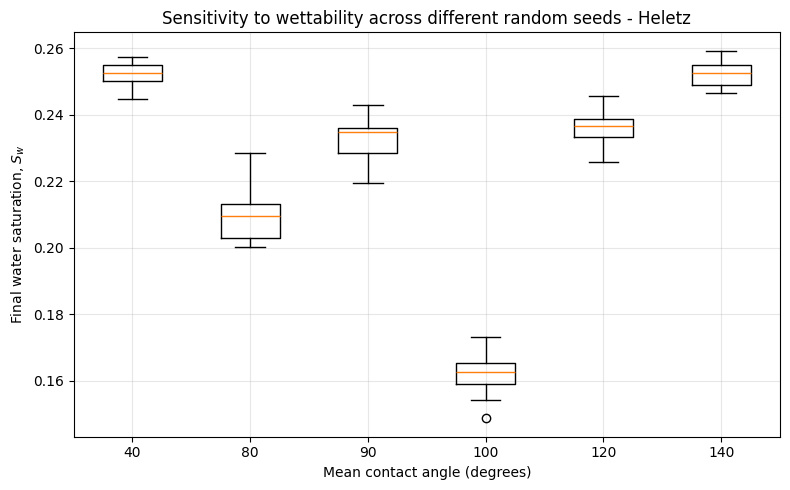

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import time
from scipy.stats import truncnorm
import os
import heapq

# ============================
# CONFIGURATION (Batch Sensitivity)
# ============================
NETWORK_PATH = 'processed_network'          # مسیر شبکه
SEED_LIST = [
    42, 101, 202, 303, 404,
    505, 606, 707, 808, 909,
    111, 222, 333, 444, 555,
    666, 777, 888, 999, 1234
]
#[42, 101, 202, 303, 404]       # لیست seedها
THETA_MEANS = [40, 80, 90, 100, 120, 140]  # میانگین زوایای تماس (درجه)
STD_ANGLE = 10                              # انحراف معیار زاویه
DP_PER_STEP = 100                            # گام فشار (kPa)
Pc_max = 50000.0                             # فشار نهایی
CONVERGENCE_PATIENCE = 60

gamma_ow = 0.051
Lambda_ref = 1.0
w1_scale = 1.0
beta_pc = 1.0

# ============================
# 1. بارگذاری شبکه (یک بار)
# ============================
def load_and_filter_network(network_path='processed_network', node1_file='node1.dat'):
    # همان تابع بارگذاری قبلی (بدون تغییر)
    with np.load(os.path.join(network_path, 'processed_network.npz'), allow_pickle=True) as data:
        pore_coords = data['pore_coords']
        pore_radii = data['pore_radii']
        pore_volumes = data['pore_volumes']
        neighbor_indices = data['neighbor_indices']
        neighbor_pointers = data['neighbor_pointers']
        throat_data = data['throat_data'] if 'throat_data' in data else np.array([])
        num_pores = int(data['num_pores'])

    neighbor_list_orig = []
    for i in range(num_pores):
        start = neighbor_pointers[i]
        end = neighbor_pointers[i+1]
        neighbor_list_orig.append(neighbor_indices[start:end].tolist())

    with open(node1_file, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip().split()
    num_pores_file = int(first_line[0])
    assert num_pores_file == num_pores

    inlet_pores_full = []
    outlet_pores_full = []
    for idx, line in enumerate(lines[1:1+num_pores]):
        parts = list(map(float, line.strip().split()))
        num_conn = int(parts[4])
        start_idx = 5 + num_conn
        inlet_status = int(parts[start_idx]) if len(parts) > start_idx else 0
        outlet_status = int(parts[start_idx+1]) if len(parts) > start_idx+1 else 0
        if inlet_status == 1:
            inlet_pores_full.append(idx)
        if outlet_status == 1:
            outlet_pores_full.append(idx)

    full_adj_all = [[] for _ in range(num_pores)]
    for i in range(num_pores):
        for neighbor_orig in neighbor_list_orig[i]:
            if neighbor_orig > 0:
                j = neighbor_orig - 1
                full_adj_all[i].append(j)

    visited = set()
    q = deque()
    for idx in inlet_pores_full + outlet_pores_full:
        if idx not in visited:
            q.append(idx)
            visited.add(idx)
    while q:
        u = int(q.popleft())
        for v in full_adj_all[u]:
            if v not in visited:
                visited.add(v)
                q.append(v)

    connected_full = np.array(sorted(visited), dtype=int)
    print(f"Network loaded: {len(connected_full)} connected pores out of {num_pores}")
    return {
        'pore_coords': pore_coords,
        'pore_radii': pore_radii,
        'pore_volumes': pore_volumes,
        'throat_data': throat_data,
        'num_pores': num_pores,
        'connected_full': connected_full,
        'inlet_pores_full': inlet_pores_full,
        'outlet_pores_full': outlet_pores_full
    }

net = load_and_filter_network(NETWORK_PATH, 'node1.dat')
connected_full = net['connected_full']
num_connected = len(connected_full)
full2new = {full: new for new, full in enumerate(connected_full)}

pore_radii_con = net['pore_radii'][connected_full]
pore_volumes_con = net['pore_volumes'][connected_full]
pore_areas_con = 4.0 * np.pi * pore_radii_con**2

# ============================
# 2. ساخت گراف و مخازن (ثابت)
# ============================
adj_con = [[] for _ in range(num_connected)]
edges_con = []
edge_throat_radius_con = []
edge_throat_area_con = []
edge_map = {}

throat_data = net['throat_data']
for t in throat_data:
    p1_orig = int(t[0])
    p2_orig = int(t[1])
    idx1 = p1_orig - 1
    idx2 = p2_orig - 1
    if idx1 in full2new and idx2 in full2new:
        u = full2new[idx1]
        v = full2new[idx2]
        r_t = t[2]
        area_t = np.pi * r_t**2
        key = (min(u, v), max(u, v))
        if key not in edge_map:
            edge_map[key] = len(edges_con)
            edges_con.append((u, v))
            edge_throat_radius_con.append(r_t)
            edge_throat_area_con.append(area_t)
            adj_con[u].append(v)
            adj_con[v].append(u)

num_edges_con = len(edges_con)

IDX_WATER_RES = num_connected
IDX_OIL_RES = num_connected + 1
num_total = num_connected + 2

# اتصال مخازن به حفره‌های ورودی/خروجی (ثابت)
full_adj_con = [[] for _ in range(num_total)]
for u, v in edges_con:
    full_adj_con[u].append(v)
    full_adj_con[v].append(u)

for full_idx in net['inlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_WATER_RES)
        full_adj_con[IDX_WATER_RES].append(u)

for full_idx in net['outlet_pores_full']:
    if full_idx in full2new:
        u = full2new[full_idx]
        full_adj_con[u].append(IDX_OIL_RES)
        full_adj_con[IDX_OIL_RES].append(u)

bottom_source_set = {IDX_WATER_RES}
top_source_set = {IDX_OIL_RES}

# ============================
# 3. تابع کمکی تولید زاویه با حفظ ساختار فضایی
# ============================
def generate_contact_angles_spatial_fixed(U, mean_deg, std_deg, a_deg=0, b_deg=180):
    a_tr = (np.radians(a_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    b_tr = (np.radians(b_deg) - np.radians(mean_deg)) / np.radians(std_deg)
    theta_rad = truncnorm.ppf(U, a_tr, b_tr, loc=np.radians(mean_deg), scale=np.radians(std_deg))
    return np.degrees(theta_rad)

# ============================
# 4. تابع اجرای یک شبیه‌سازی تخلیه و برگرداندن Sw نهایی
# ============================
def run_drainage(theta_deg_con):
    # حالت اولیه (همه آب)
    state = np.zeros(num_connected, dtype=int)
    ghost_state = np.zeros(num_total, dtype=int)
    ghost_state[IDX_WATER_RES] = 0
    ghost_state[IDX_OIL_RES] = 1
    ghost_state[:num_connected] = state

    water_connected = np.zeros(num_connected, dtype=bool)
    # فقط چون Lambda_ref>0 است، TRAPPING_ON فعال است (فرض می‌کنیم Lambda_ref=1)
    TRAPPING_ON = True

    def initialize_water_connected():
        visited = set()
        q = deque([IDX_WATER_RES])
        visited.add(IDX_WATER_RES)
        while q:
            u = q.popleft()
            for v in full_adj_con[u]:
                if v not in visited and ghost_state[v] == 0:
                    visited.add(v)
                    q.append(v)
        for i in range(num_connected):
            water_connected[i] = (i in visited)

    initialize_water_connected()

    def is_still_connected(v, blocked_node):
        visited = set()
        q = deque([v])
        while q:
            cur = q.popleft()
            if cur in visited:
                continue
            visited.add(cur)
            if cur == IDX_WATER_RES:
                return True, visited
            if cur != v and cur < num_connected and water_connected[cur]:
                return True, visited
            for w in full_adj_con[cur]:
                if w == blocked_node:
                    continue
                if ghost_state[w] == 0 and w not in visited:
                    q.append(w)
        return False, visited

    def update_water_connectivity_after_flip(u):
        for v in adj_con[u]:
            if state[v] == 0 and water_connected[v]:
                connected, visited_set = is_still_connected(v, u)
                if not connected:
                    for node in visited_set:
                        if node < num_connected:
                            water_connected[node] = False

    def get_min_throat_to_source(u, state, source_set, target_label=0):
        visited = {u}
        q = deque([(u, float('inf'))])
        while q:
            cur, r_min = q.popleft()
            if cur in source_set:
                return r_min
            for v in full_adj_con[cur]:
                if v not in visited and ghost_state[v] == target_label:
                    if cur < num_connected and v < num_connected:
                        key = (min(cur, v), max(cur, v))
                        r_t = edge_throat_radius_con[edge_map[key]] if key in edge_map else 1e-6
                    else:
                        r_t = 1e-3
                    new_min = min(r_min, r_t)
                    visited.add(v)
                    q.append((v, new_min))
        return pore_radii_con[u] * 0.5

    def compute_delta_J_drain(u, state, Pc):
        d_wett = w1_scale * gamma_ow * np.cos(np.deg2rad(theta_deg_con[u])) * pore_areas_con[u]
        d_iface = 0.0
        for v in adj_con[u]:
            t_v = state[v] if v < num_connected else ghost_state[v]
            delta = abs(1 - t_v) - abs(0 - t_v)
            key = (min(u, v), max(u, v))
            area = edge_throat_area_con[edge_map[key]] if key in edge_map else np.pi * (min(pore_radii_con[u], 1e-6))**2
            d_iface += 1.0 * gamma_ow * area * delta   # w2=1

        penalty = 0.0
        original_connected = water_connected.copy()
        ghost_state[u] = 1
        triggers_trap = False
        for v in adj_con[u]:
            if state[v] == 0 and original_connected[v]:
                connected, _ = is_still_connected(v, u)
                if not connected:
                    triggers_trap = True
                    break
        ghost_state[u] = 0

        if triggers_trap:
            r_min = get_min_throat_to_source(u, state, bottom_source_set, target_label=0)
            penalty = Lambda_ref * gamma_ow * pore_areas_con[u] * (r_min / pore_radii_con[u])**2   # اصلاح: حجم

        d_pc = -beta_pc * Pc * pore_volumes_con[u]
        return d_wett + d_iface + penalty + d_pc

    # ساخت frontier اولیه
    frontier = set()
    for u in range(num_connected):
        if state[u] == 0 and water_connected[u]:
            if any(ghost_state[v] == 1 for v in full_adj_con[u]):
                frontier.add(u)

    # صف اولویت
    heap = []
    def push_to_heap(u, pc):
        dJ = compute_delta_J_drain(u, state, pc)
        heapq.heappush(heap, (dJ, u))

    Pc = 0.0
    for u in frontier:
        push_to_heap(u, Pc)

    while Pc <= Pc_max:
        if not heap or heap[0][0] >= 0.0:
            Pc += DP_PER_STEP
            if Pc > Pc_max:
                Pc = Pc_max
            # بازسازی صف با فشار جدید
            heap.clear()
            for u in frontier:
                if state[u] == 0 and water_connected[u]:
                    push_to_heap(u, Pc)
            if Pc >= Pc_max and (not heap or heap[0][0] >= 0.0):
                break
            continue

        dJ, u = heapq.heappop(heap)
        if state[u] != 0 or not water_connected[u]:
            continue
        if dJ < 0.0:
            state[u] = 1
            ghost_state[u] = 1
            water_connected[u] = False
            frontier.discard(u)
            update_water_connectivity_after_flip(u)
            for v in adj_con[u]:
                if state[v] == 0:
                    frontier.add(v)
                    if water_connected[v]:
                        push_to_heap(v, Pc)

    Sw_final = np.mean(state == 0)
    return Sw_final

# ============================
# 5. اجرای حلقه بر روی seedها و میانگین‌ها
# ============================
results = np.zeros((len(SEED_LIST), len(THETA_MEANS)))
for i, seed in enumerate(SEED_LIST):
    np.random.seed(seed)
    U = np.random.uniform(0, 1, net['num_pores'])   # ساختار فضایی ویژه این seed
    for j, mean_deg in enumerate(THETA_MEANS):
        theta_full = generate_contact_angles_spatial_fixed(U, mean_deg=mean_deg, std_deg=STD_ANGLE)
        theta_deg_con = theta_full[connected_full]
        Sw = run_drainage(theta_deg_con)
        results[i, j] = Sw
        print(f"Seed {seed}, mean θ = {mean_deg}° → Sw = {Sw:.4f}")

# ============================
# 6. ذخیره و نمایش نتایج
# ============================
np.savez('sensitivity_resultsHeletz.npz', seeds=SEED_LIST, theta_means=THETA_MEANS, Sw_matrix=results)
print("\nFinal Sw matrix (rows: seeds, columns: θ means):")
print(results)

# رسم نمودار جعبه‌ای (boxplot) برای نمایش تغییرات
plt.figure(figsize=(8,5))
plt.boxplot(results, labels=THETA_MEANS)
plt.xlabel('Mean contact angle (degrees)')
plt.ylabel('Final water saturation, $S_w$')
plt.title('Sensitivity to wettability across different random seeds - Heletz')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# بارگذاری نتایج
data = np.load('sensitivity_resultsHeletz.npz')
theta_means = data['theta_means']        # آرایه زوایا
Sw_matrix = data['Sw_matrix']            # (n_seeds × n_angles)

# محاسبه آماره‌ها
mean_sw = np.mean(Sw_matrix, axis=0)
std_sw  = np.std(Sw_matrix, axis=0, ddof=1)   # انحراف معیار نمونه‌ای
cv_sw   = (std_sw / mean_sw) * 100

# چاپ جدول
print(f"{'θ(°)':<10} {'Mean Sw':<10} {'Std':<10} {'CV(%)':<10}")
print('-' * 40)
for i, th in enumerate(theta_means):
    print(f"{th:<10} {mean_sw[i]:<10.4f} {std_sw[i]:<10.4f} {cv_sw[i]:<10.2f}")

θ(°)       Mean Sw    Std        CV(%)     
----------------------------------------
40         0.2521     0.0038     1.52      
80         0.2093     0.0068     3.27      
90         0.2321     0.0067     2.88      
100        0.1625     0.0061     3.78      
120        0.2360     0.0053     2.23      
140        0.2524     0.0037     1.47      
